# سامانه‌ی هشدار زودهنگام سکته‌ی مغزی
**تحلیل داده، طراحی الگوریتم و یادگیری عمیق با پایتون**

**دانشجو: مینا خسروی**

این نوت‌بوک از ابتدا تا انتها قابل اجراست (Run All)

| فاز | موضوع |
|---|---|
| ۱ | شناخت و پاک‌سازی داده |
| ۲ | تحلیل اکتشافی (EDA) |
| ۳ | آماده‌سازی داده (بدون نشت اطلاعات) |
| ۴ | مدل پایه (Random Forest) |
| ۵ | رگرسیون لجستیک از صفر با NumPy |
| ۶ | مقابله با عدم توازن کلاس‌ها |
| ۷ | شبکه‌ی عمیق با Keras |
| ۸ | ارزیابی نهایی و تفسیر |

**نکته درباره‌ی نام ستون‌ها:** فایل دیتاست (نسخه‌ی Kaggle) نام‌های اصلی را دارد و در صورت پروژه نام‌ها کمی متفاوت نوشته شده‌اند (مثلاً `heart_disease` = `disease_heart`). این دو یکی هستند.

**اصل رعایت‌شده در کل پروژه:** مجموعه‌ی آزمون فقط برای گزارش نهایی استفاده می‌شود. انتخاب مدل نهایی و آستانه‌ی تصمیم‌گیری با داده‌ی آموزش (اعتبارسنجی متقاطع) انجام می‌شود.

## مرحله‌ی صفر: کتابخانه‌ها

In [1]:
import os, sys, importlib, subprocess, warnings, shutil, glob
warnings.filterwarnings("ignore")

def ensure(pkg, mod):
    # اگر کتابخانه نصب نباشد با pip نصب می‌شود
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"در حال نصب {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("imbalanced-learn", "imblearn"); ensure("tensorflow", "tensorflow"); ensure("seaborn", "seaborn")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)
COL_PATIENT, COL_HEALTHY = "#d62728", "#1f77b4"     # بیمار قرمز، سالم آبی (در کل پروژه ثابت)
PLOT_DIR = "results/figures"
os.makedirs(PLOT_DIR, exist_ok=True)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

def save_show(name, interpretation):
    # ذخیره با dpi=200، نمایش و چاپ جمله‌ی تفسیر
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("این نمودار نشان می‌دهد که", interpretation)

def legend_for(ax, labels_colors, **kw):
    # ساخت Legend دستی برای نمودارهایی که خودشان راهنما ندارند
    ax.legend(handles=[Patch(color=c, label=l) for l, c in labels_colors], **kw)

print("آماده‌ایم")

آماده‌ایم


## فاز ۱ — شناخت و پاک‌سازی داده
فایل `healthcare-dataset-stroke-data.csv` باید کنار نوت‌بوک یا داخل پوشه‌ی data باشد (در Colab در صورت نبودن، پنجره‌ی آپلود باز می‌شود).

In [2]:
CSV_NAME = "healthcare-dataset-stroke-data.csv"
# اول کنار نوت‌بوک می‌گردد، بعد داخل پوشه‌ی data/
for cand in [CSV_NAME, f"data/{CSV_NAME}"]:
    if os.path.exists(cand):
        CSV_NAME = cand
        break
else:
    try:
        from google.colab import files
        print("لطفاً فایل CSV را آپلود کنید ...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{CSV_NAME} پیدا نشد. آن را از Kaggle دانلود کنید و داخل پوشه‌ی data بگذارید.")

df = pd.read_csv(CSV_NAME)
print("ابعاد داده (سطر، ستون):", df.shape)
print("\nنوع هر ستون:"); print(df.dtypes)
df.head()

لطفاً فایل CSV را آپلود کنید ...


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
ابعاد داده (سطر، ستون): (5110, 12)

نوع هر ستون:
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print("آمار توصیفی ستون‌های عددی:")
display(df.describe().T.round(2))
print("\nتعداد مقادیر هر دسته در ستون‌های متنی:")
for col in ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]:
    print(f"\n{col}:"); print(df[col].value_counts())

آمار توصیفی ستون‌های عددی:


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.83,21161.72,67.00,17741.25,36932.00,54682.00,72940.00
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00



تعداد مقادیر هر دسته در ستون‌های متنی:

gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


**۱-الف) نسبت بیماران به سالم‌ها**

سالم: 4861 نفر (95.13%) | سکته: 249 نفر (4.87%)
به ازای هر بیمار، 19.5 نفر سالم داریم.


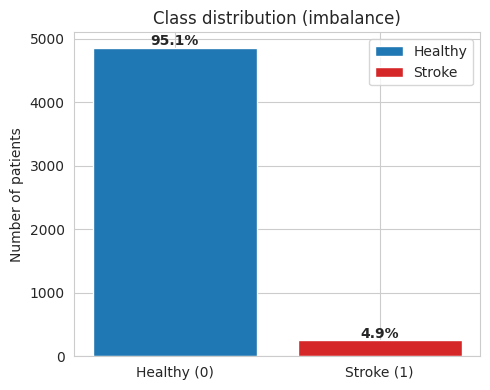

این نمودار نشان می‌دهد که فقط حدود ۵٪ بیماران سکته کرده‌اند؛ داده به شدت نامتوازن است.


In [4]:
counts = df["stroke"].value_counts().sort_index()
pct = counts / counts.sum() * 100
print(f"سالم: {counts[0]} نفر ({pct[0]:.2f}%) | سکته: {counts[1]} نفر ({pct[1]:.2f}%)")
print(f"به ازای هر بیمار، {counts[0]/counts[1]:.1f} نفر سالم داریم.")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Healthy (0)", "Stroke (1)"], counts.values, color=[COL_HEALTHY, COL_PATIENT])
for b, p in zip(bars, pct.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 40, f"{p:.1f}%", ha="center", fontweight="bold")
ax.set_title("Class distribution (imbalance)"); ax.set_ylabel("Number of patients")
ax.legend(bars, ["Healthy", "Stroke"], loc="upper right")
save_show("01_class_distribution", "فقط حدود ۵٪ بیماران سکته کرده‌اند؛ داده به شدت نامتوازن است.")

**پاسخ: نسبت کلاس‌ها چقدر است و چرا مشکل‌ساز است؟**
فقط حدود ۴٫۹٪ نمونه‌ها (۲۴۹ از ۵۱۱۰) سکته کرده‌اند و حدود ۹۵٪ سالم‌اند. مدل هنگام آموزش می‌خواهد خطا را کم کند و ساده‌ترین راه این است که همیشه «سالم» پیش‌بینی کند و ۹۵٪ مواقع درست باشد. در نتیجه مدل کلاس بیمار را نادیده می‌گیرد، در حالی که همین کلاس برای بیمارستان مهم‌ترین است.

**۱-ب) مقادیر گمشده**
مقدار گمشده‌ی `bmi` در فایل به‌صورت متن `N/A` نوشته شده که pandas آن را `NaN` می‌خواند. ستون `smoking_status` هم مقداری به نام `Unknown` دارد که یک «گمشده‌ی پنهان» است.

تعداد مقادیر گمشده در هر ستون:
bmi    201
dtype: int64

درصد گمشده‌ی bmi: 3.9%
تعداد Unknown در smoking_status: 1544 (30.2%)


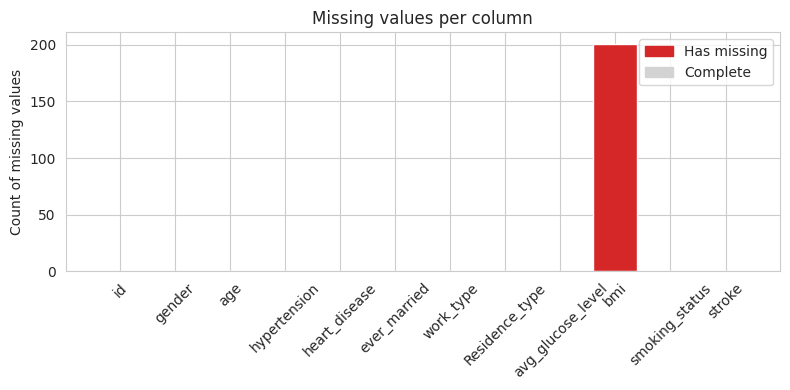

این نمودار نشان می‌دهد که فقط ستون bmi مقدار گمشده دارد (حدود ۲۰۱ مورد، ۳٫۹٪).


In [5]:
missing = df.isna().sum()
print("تعداد مقادیر گمشده در هر ستون:")
print(missing[missing > 0] if (missing > 0).any() else "هیچ")
print(f"\nدرصد گمشده‌ی bmi: {missing['bmi']/len(df)*100:.1f}%")
print(f"تعداد Unknown در smoking_status: {(df['smoking_status']=='Unknown').sum()} ({(df['smoking_status']=='Unknown').mean()*100:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(missing.index, missing.values, color=[COL_PATIENT if v > 0 else "lightgray" for v in missing.values])
ax.set_title("Missing values per column"); ax.set_ylabel("Count of missing values")
ax.tick_params(axis="x", rotation=45)
legend_for(ax, [("Has missing", COL_PATIENT), ("Complete", "lightgray")])
save_show("02_missing_values", "فقط ستون bmi مقدار گمشده دارد (حدود ۲۰۱ مورد، ۳٫۹٪).")

**پاسخ: کدام ستون مقدار گمشده دارد؟ چرا میانه یا میانگین؟**
فقط `bmi` (۲۰۱ مورد). برای پر کردن از **میانه** استفاده می‌کنیم، چون توزیع BMI چولگی راست دارد و مقادیر بسیار بزرگ (تا ۹۷٫۶) میانگین را بالا می‌کشند، در حالی که میانه به مقادیر پرت حساس نیست.

**نشت داده:** میانه‌ی پرکردن باید فقط از داده‌ی آموزش محاسبه شود؛ پس پر کردن واقعی در فاز ۳ و بعد از تقسیم انجام می‌شود. برای نمودارهای فاز ۲ فقط یک نسخه‌ی موقت `df_eda` می‌سازیم که هرگز وارد مدل‌سازی نمی‌شود.

**۱-پ) مقادیر غیرعادی (Outliers)**

چولگی (skewness) ستون bmi: 1.06 (عدد مثبت بزرگ = دنباله‌ی بلند سمت راست)
age: 0 مقدار پرت به روش IQR
avg_glucose_level: 627 مقدار پرت به روش IQR
bmi: 110 مقدار پرت به روش IQR

سطرهای با gender = Other: 1
تعداد bmi بزرگ‌تر از 60: 13 | بیشینه‌ی bmi: 97.6
تعداد بیماران زیر ۲ سال: 120
سکته در بیماران bmi>60: 0 مورد


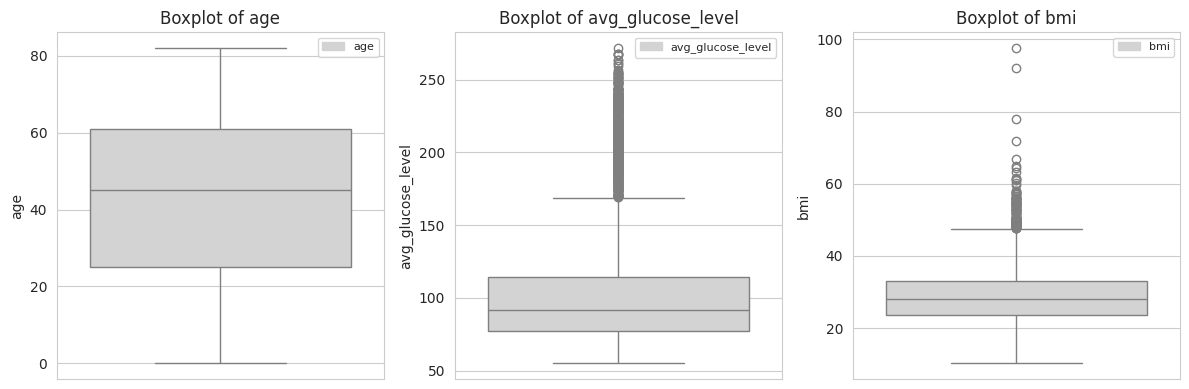

این نمودار نشان می‌دهد که قند خون و BMI مقادیر پرت زیادی دارند ولی سن چنین مشکلی ندارد.


In [6]:
print("چولگی (skewness) ستون bmi:", round(df["bmi"].skew(), 2), "(عدد مثبت بزرگ = دنباله‌ی بلند سمت راست)")

def iqr_outliers(s):
    # روش IQR: مقدار بیرون از [Q1-1.5*IQR , Q3+1.5*IQR] پرت است
    q1, q3 = s.quantile(0.25), s.quantile(0.75); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

for c in ["age", "avg_glucose_level", "bmi"]:
    print(f"{c}: {iqr_outliers(df[c].dropna())} مقدار پرت به روش IQR")
print("\nسطرهای با gender = Other:", (df['gender'] == 'Other').sum())
print("تعداد bmi بزرگ‌تر از 60:", (df['bmi'] > 60).sum(), "| بیشینه‌ی bmi:", df['bmi'].max())
print("تعداد بیماران زیر ۲ سال:", (df['age'] < 2).sum())
print("سکته در بیماران bmi>60:", df.loc[df['bmi'] > 60, 'stroke'].sum(), "مورد")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, c in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.boxplot(y=df[c], ax=ax, color="lightgray")
    ax.set_title(f"Boxplot of {c}"); legend_for(ax, [(c, "lightgray")], loc="upper right", fontsize=8)
save_show("03_outliers_boxplots", "قند خون و BMI مقادیر پرت زیادی دارند ولی سن چنین مشکلی ندارد.")

**تصمیم درباره‌ی پرت‌ها:**
- **قند خون و BMI:** مقادیر بالا از نظر پزشکی ممکن‌اند (دیابت شدید، چاقی مفرط) و دقیقاً همین بیماران پرخطرند؛ حذفشان اطلاعات مهم را از بین می‌برد، پس نگه داشته می‌شوند.
- **سن زیر ۲ سال:** سن‌های اعشاری (مثل ۰٫۰۸) مربوط به نوزادان است و خطا نیست؛ نگه داشته می‌شود.
- **`gender = Other`:** فقط ۱ سطر است و چیزی به مدل یاد نمی‌دهد؛ حذف می‌شود.
- **ستون `id`:** بی‌مصرف است؛ حذف می‌شود.

**۱-ت) وضعیت Unknown در smoking_status**

In [7]:
smoke_summary = df.groupby("smoking_status").agg(
    count=("stroke", "size"), mean_age=("age", "mean"), stroke_rate_pct=("stroke", lambda s: s.mean()*100)).round(2)
display(smoke_summary)
unk = df["smoking_status"] == "Unknown"
print(f"\nدر گروه Unknown: {(df.loc[unk,'age']<18).mean()*100:.0f}% زیر ۱۸ سال هستند")
print(f"در سایر گروه‌ها:  {(df.loc[~unk,'age']<18).mean()*100:.0f}% زیر ۱۸ سال هستند")

,count,mean_age,stroke_rate_pct
smoking_status,,,
Unknown,1544,30.23,3.04
formerly smoked,885,54.93,7.91
never smoked,1892,46.74,4.76
smokes,789,47.10,5.32



در گروه Unknown: 44% زیر ۱۸ سال هستند
در سایر گروه‌ها:  5% زیر ۱۸ سال هستند


**پاسخ: Unknown را چگونه مدیریت کردید و چرا؟**
حدود ۳۰٪ داده Unknown است. حذفشان ۳۰٪ داده را از بین می‌برد و پر کردن با «مد» یک حدس بی‌پایه درباره‌ی سیگار کشیدن افراد (به‌ویژه کودکان) است. جدول بالا نشان می‌دهد این گروه میانگین سنی پایین‌تری دارد و شامل کودکان زیادی است، یعنی «ناشناخته بودن» خودش اطلاعات دارد. پس Unknown به‌عنوان **یک دسته‌ی مستقل** نگه داشته می‌شود و در One-Hot ستون جدا می‌گیرد.

In [8]:
df_clean = df.drop(columns=["id"])
df_clean = df_clean[df_clean["gender"] != "Other"].reset_index(drop=True)
print("ابعاد بعد از پاک‌سازی:", df_clean.shape)

# نسخه‌ی موقت فقط برای EDA (bmi با میانه‌ی کل داده پر شده؛ وارد مدل نمی‌شود)
df_eda = df_clean.copy()
df_eda["bmi"] = df_eda["bmi"].fillna(df_eda["bmi"].median())
df_eda["stroke_label"] = df_eda["stroke"].map({0: "Healthy", 1: "Stroke"})
print("مقادیر گمشده‌ی df_eda:", int(df_eda.drop(columns='stroke_label').isna().sum().sum()))

ابعاد بعد از پاک‌سازی: (5109, 11)
مقادیر گمشده‌ی df_eda: 0


## فاز ۲ — تحلیل اکتشافی (EDA)
«نرخ سکته» یعنی چند درصد افراد هر گروه سکته کرده‌اند.

**۲-الف) نرخ سکته به تفکیک گروه سنی**

age_group
0-17      0.23
18-29     0.00
30-39     0.92
40-49     1.64
50-59     5.76
60-69     7.57
70-79    16.52
80+      21.51
Name: stroke, dtype: float64


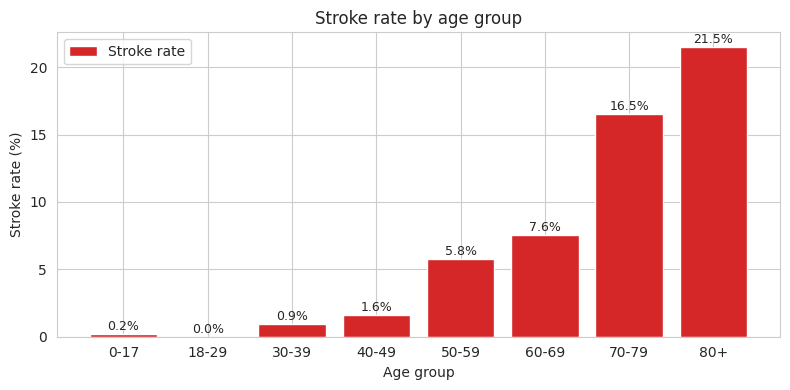

این نمودار نشان می‌دهد که با بالا رفتن سن، نرخ سکته به‌شدت زیاد می‌شود و در گروه‌های سنی بالا چندین برابر گروه‌های جوان است.


In [9]:
bins = [0, 18, 30, 40, 50, 60, 70, 80, 120]
labels = ["0-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
df_eda["age_group"] = pd.cut(df_eda["age"], bins=bins, labels=labels, right=False)
rate_age = df_eda.groupby("age_group", observed=True)["stroke"].mean() * 100
print(rate_age.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(rate_age.index.astype(str), rate_age.values, color=COL_PATIENT)
for b, v in zip(bars, rate_age.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_title("Stroke rate by age group"); ax.set_xlabel("Age group"); ax.set_ylabel("Stroke rate (%)")
ax.legend(bars[:1], ["Stroke rate"])
save_show("04_stroke_rate_by_age", "با بالا رفتن سن، نرخ سکته به‌شدت زیاد می‌شود و در گروه‌های سنی بالا چندین برابر گروه‌های جوان است.")

**۲-ب) فشار خون، بیماری قلبی و سیگار**

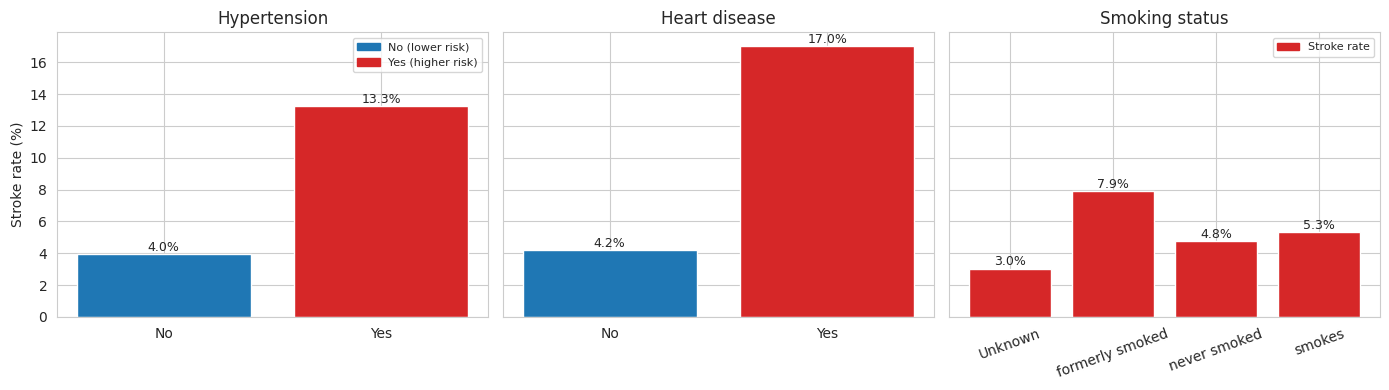

این نمودار نشان می‌دهد که فشار خون و بیماری قلبی نرخ سکته را چند برابر می‌کنند، اما اثر سیگار در این نمودار ساده شفاف نیست.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
r = df_eda.groupby("hypertension")["stroke"].mean() * 100
axes[0].bar(["No", "Yes"], r.values, color=[COL_HEALTHY, COL_PATIENT]); axes[0].set_title("Hypertension"); axes[0].set_ylabel("Stroke rate (%)")
r2 = df_eda.groupby("heart_disease")["stroke"].mean() * 100
axes[1].bar(["No", "Yes"], r2.values, color=[COL_HEALTHY, COL_PATIENT]); axes[1].set_title("Heart disease")
r3 = df_eda.groupby("smoking_status")["stroke"].mean() * 100
axes[2].bar(r3.index, r3.values, color=COL_PATIENT); axes[2].set_title("Smoking status"); axes[2].tick_params(axis="x", rotation=20)
for ax in axes:
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width()/2, p.get_height() + 0.2, f"{p.get_height():.1f}%", ha="center", fontsize=9)
legend_for(axes[0], [("No (lower risk)", COL_HEALTHY), ("Yes (higher risk)", COL_PATIENT)], fontsize=8)
legend_for(axes[2], [("Stroke rate", COL_PATIENT)], fontsize=8)
save_show("05_stroke_rate_by_risk_factors", "فشار خون و بیماری قلبی نرخ سکته را چند برابر می‌کنند، اما اثر سیگار در این نمودار ساده شفاف نیست.")

**۲-پ) مقایسه‌ی توزیع سن و قند خون در بیماران و سالم‌ها**

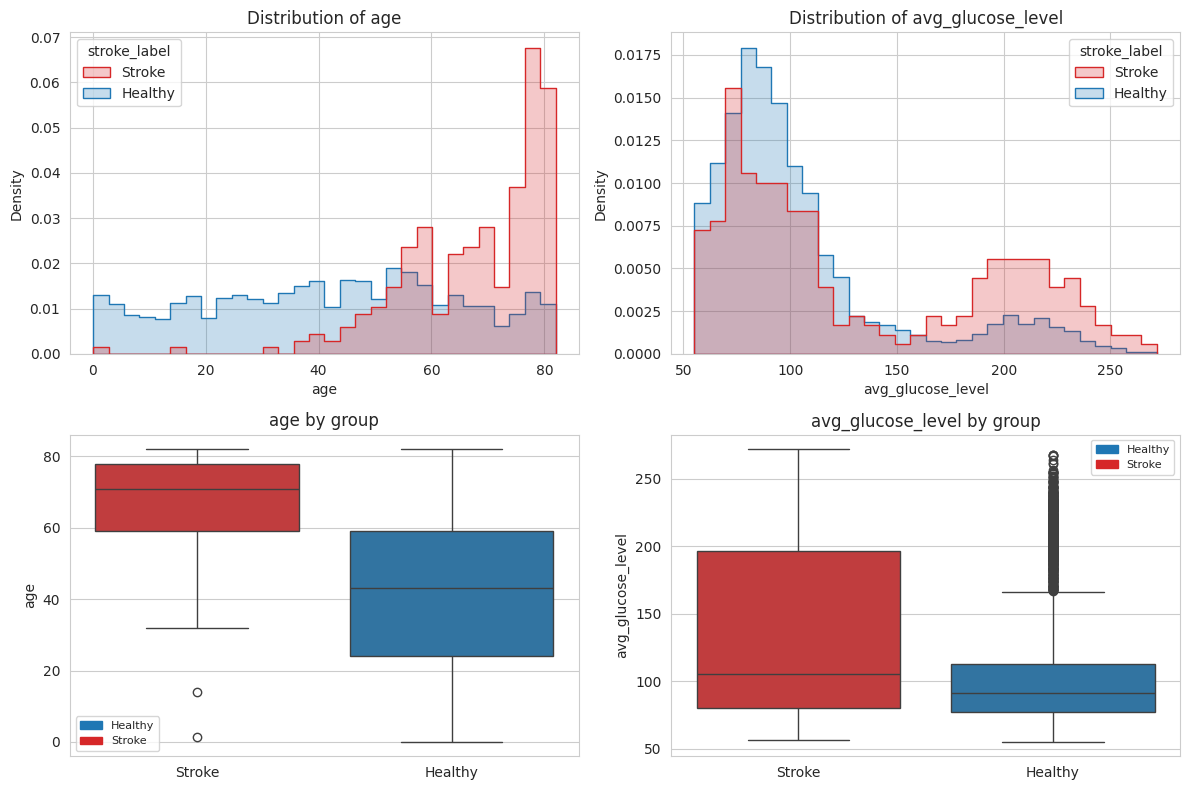

این نمودار نشان می‌دهد که بیماران به‌طور میانگین مسن‌ترند و قند خون بالاتری دارند.


In [11]:
pal = {"Healthy": COL_HEALTHY, "Stroke": COL_PATIENT}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, c in enumerate(["age", "avg_glucose_level"]):
    # common_norm=False: هر گروه جداگانه نرمال می‌شود (چون تعدادشان خیلی فرق دارد)
    sns.histplot(data=df_eda, x=c, hue="stroke_label", palette=pal, stat="density", common_norm=False, element="step", bins=30, ax=axes[0, j])
    axes[0, j].set_title(f"Distribution of {c}")
    sns.boxplot(data=df_eda, x="stroke_label", y=c, hue="stroke_label", palette=pal, legend=False, ax=axes[1, j])
    axes[1, j].set_title(f"{c} by group"); axes[1, j].set_xlabel("")
    legend_for(axes[1, j], [("Healthy", COL_HEALTHY), ("Stroke", COL_PATIENT)], fontsize=8)
save_show("06_age_glucose_distributions", "بیماران به‌طور میانگین مسن‌ترند و قند خون بالاتری دارند.")

**۲-ت) نقشه‌ی گرمایی همبستگی**

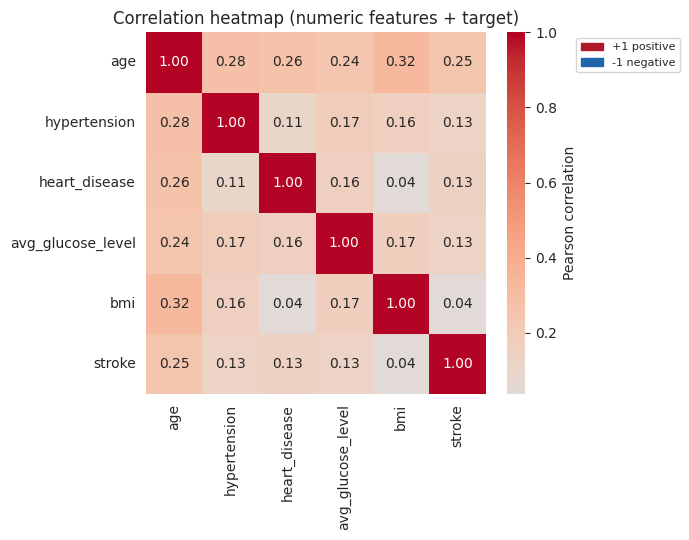

این نمودار نشان می‌دهد که سن بیشترین همبستگی را با سکته دارد و بقیه‌ی ویژگی‌ها همبستگی خطی ضعیف‌تری دارند.
bmi                  0.036
hypertension         0.128
avg_glucose_level    0.132
heart_disease        0.135
age                  0.245
Name: stroke, dtype: float64


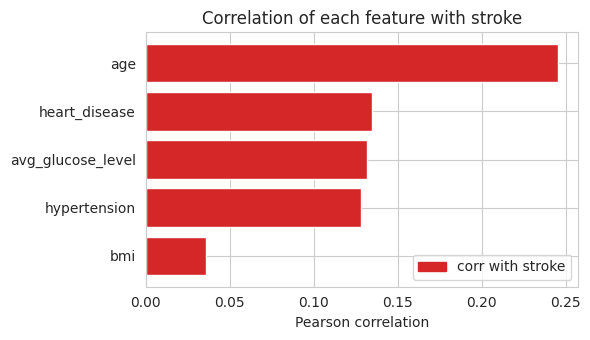

این نمودار نشان می‌دهد که سن بیشترین ارتباط را دارد و پس از آن بیماری قلبی، فشار خون و قند خون قرار دارند.


In [12]:
num_cols_eda = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
corr = df_eda[num_cols_eda].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation heatmap (numeric features + target)")
legend_for(ax, [("+1 positive", "#b2182b"), ("-1 negative", "#2166ac")], loc="upper left", bbox_to_anchor=(1.25, 1), fontsize=8)
save_show("07_correlation_heatmap", "سن بیشترین همبستگی را با سکته دارد و بقیه‌ی ویژگی‌ها همبستگی خطی ضعیف‌تری دارند.")

corr_target = corr["stroke"].drop("stroke").sort_values()
print(corr_target.round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(corr_target.index, corr_target.values, color=COL_PATIENT)
ax.set_title("Correlation of each feature with stroke"); ax.set_xlabel("Pearson correlation")
ax.legend([Patch(color=COL_PATIENT)], ["corr with stroke"], loc="lower right")
save_show("08_top_correlated_features", "سن بیشترین ارتباط را دارد و پس از آن بیماری قلبی، فشار خون و قند خون قرار دارند.")

**پاسخ: کدام سه عامل بیشترین ارتباط را با سکته دارند؟**
بر اساس نمودار بالا: ۱) **سن** (با اختلاف زیاد، ۰٫۲۴۵)، ۲) **بیماری قلبی** (۰٫۱۳۵)، ۳) **قند خون** (۰٫۱۳۲). فشار خون (۰٫۱۲۸) بسیار نزدیک به سوم است. BMI همبستگی خطی ضعیفی دارد.

حالا بخش «متعجب‌کننده» را با داده بررسی می‌کنیم:

In [13]:
print("نرخ سکته (%) به تفکیک چند ویژگی:\n")
for c in ["gender", "Residence_type", "ever_married", "smoking_status", "work_type"]:
    print(df_eda.groupby(c)["stroke"].mean().mul(100).round(2).to_string(), "\n")
print(df_eda.groupby("smoking_status").agg(mean_age=("age","mean"), stroke_rate=("stroke","mean")).round(3))
print(df_eda.groupby("ever_married").agg(mean_age=("age","mean"), stroke_rate=("stroke","mean")).round(3))

نرخ سکته (%) به تفکیک چند ویژگی:

gender
Female    4.71
Male      5.11 

Residence_type
Rural    4.54
Urban    5.20 

ever_married
No     1.65
Yes    6.56 

smoking_status
Unknown            3.04
formerly smoked    7.92
never smoked       4.76
smokes             5.32 

work_type
Govt_job         5.02
Never_worked     0.00
Private          5.10
Self-employed    7.94
children         0.29 

                 mean_age  stroke_rate
smoking_status                        
Unknown            30.230        0.030
formerly smoked    54.963        0.079
never smoked       46.745        0.048
smokes             47.096        0.053
              mean_age  stroke_rate
ever_married                       
No              22.012        0.017
Yes             54.342        0.066


**پاسخ: چه چیزی متعجب‌کننده بود؟**
1. **سیگار:** انتظار می‌رفت «سیگاری‌ها» بالاترین نرخ را داشته باشند، ولی «سیگاری سابق» (۷٫۹٪) از «سیگاری فعلی» (۵٫۳٪) بالاتر است. دلیل آن **سن** است: میانگین سن سیگاری‌های سابق حدود ۵۵ سال و سیگاری‌های فعلی حدود ۴۷ سال است. این یک **متغیر مخدوش‌کننده** است. گروه Unknown کمترین نرخ را دارد چون کودکان زیادی دارد.
2. **ازدواج:** افراد متأهل نرخ سکته بسیار بالاتری دارند (۶٫۶٪ در برابر ۱٫۷٪)، اما دلیل واقعی سن است (میانگین سن ۵۴ در برابر ۲۲ سال)، نه خود ازدواج.
3. **جنسیت و محل سکونت** تقریباً تفاوتی ایجاد نمی‌کنند.
4. **BMI** که معمولاً عامل خطر شناخته می‌شود، در این داده همبستگی خطی ضعیفی دارد.

## فاز ۳ — آماده‌سازی داده (بدون نشت اطلاعات)
هر چیزی که از داده «یاد گرفته می‌شود» (میانه‌ی bmi، میانگین و انحراف معیار، SMOTE) فقط روی آموزش fit می‌شود و سپس روی آزمون اعمال می‌شود.

ترتیب: ۱) One-Hot ← ۲) تقسیم ۸۰/۲۰ با `stratify` ← ۳) پر کردن bmi با میانه‌ی آموزش ← ۴) استانداردسازی با آمار آموزش ← ۵) جداکردن بخش اعتبارسنجی از آموزش.
(One-Hot چیزی از مقادیر داده یاد نمی‌گیرد، پس قبل از تقسیم هم نشت ایجاد نمی‌کند.)

In [14]:
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
# drop_first=True یک ستون اضافه را برای جلوگیری از هم‌خطی حذف می‌کند
X = pd.get_dummies(df_clean.drop(columns="stroke"), columns=cat_cols, drop_first=True, dtype=float)
y = df_clean["stroke"].values
print("تعداد ویژگی‌ها بعد از One-Hot:", X.shape[1]); print(list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.copy(), X_test.copy()
raw_train = df_eda.loc[X_train.index].copy()      # نسخه‌ی خام آموزش فقط برای نمودارهای خوانا
assert (raw_train["stroke"].values == y_train).all(), "ردیف‌ها هم‌تراز نیستند!"
print(f"آموزش: {len(X_train)} | درصد بیمار: {y_train.mean()*100:.2f}%")
print(f"آزمون: {len(X_test)} | درصد بیمار: {y_test.mean()*100:.2f}%")

تعداد ویژگی‌ها بعد از One-Hot: 15
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']
آموزش: 4087 | درصد بیمار: 4.87%
آزمون: 1022 | درصد بیمار: 4.89%


In [15]:
# پر کردن bmi: میانه فقط از آموزش (fit) و اعمال روی هر دو (transform)
imputer = SimpleImputer(strategy="median").fit(X_train[["bmi"]])
print("میانه‌ی bmi در آموزش:", round(float(imputer.statistics_[0]), 2))
X_train["bmi"] = imputer.transform(X_train[["bmi"]]); X_test["bmi"] = imputer.transform(X_test[["bmi"]])

# استانداردسازی فقط با آمار آموزش
num_cols = ["age", "avg_glucose_level", "bmi"]
scaler = StandardScaler().fit(X_train[num_cols])
X_train[num_cols] = scaler.transform(X_train[num_cols]); X_test[num_cols] = scaler.transform(X_test[num_cols])
print("\nمیانگین ستون‌های عددی در آموزش (≈ 0):"); print(X_train[num_cols].mean().round(3).to_string())
print("\nمیانگین در آزمون (دقیقاً صفر نیست؛ یعنی از آزمون چیزی یاد نگرفته‌ایم ):"); print(X_test[num_cols].mean().round(3).to_string())
print("\nمقادیر گمشده‌ی باقی‌مانده:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

feature_names = X_train.columns.tolist()
X_train_np, X_test_np = X_train.values.astype(float), X_test.values.astype(float)

# بخش اعتبارسنجی (۲۰٪ آموزش): برای تنظیم هایپرپارامترها بدون دست زدن به آزمون
X_tr, X_val, y_tr, y_val = train_test_split(X_train_np, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print(f"\nآموزش‌فرعی: {len(X_tr)} | اعتبارسنجی: {len(X_val)} (بیمار: {int(y_val.sum())}) | آزمون: {len(X_test_np)} (بیمار: {int(y_test.sum())})")

میانه‌ی bmi در آموزش: 28.1

میانگین ستون‌های عددی در آموزش (≈ 0):
age                 -0.0
avg_glucose_level    0.0
bmi                 -0.0

میانگین در آزمون (دقیقاً صفر نیست؛ یعنی از آزمون چیزی یاد نگرفته‌ایم ):
age                 -0.006
avg_glucose_level    0.027
bmi                  0.008

مقادیر گمشده‌ی باقی‌مانده: 0

آموزش‌فرعی: 3269 | اعتبارسنجی: 818 (بیمار: 40) | آزمون: 1022 (بیمار: 50)


## فاز ۴ — مدل پایه (Random Forest بدون هیچ اصلاحی)
ابتدا توابع کمکی ارزیابی را تعریف می‌کنیم.

In [16]:
results, proba_dict = {}, {}     # نتایج و احتمال‌های همه‌ی مدل‌ها روی آزمون (فقط برای گزارش)

def evaluate(name, y_true, proba, threshold=0.5, store=True):
    # احتمال را با آستانه به ۰/۱ تبدیل می‌کند و همه‌ی معیارها را حساب می‌کند
    pred = (proba >= threshold).astype(int)
    m = {"Accuracy":  float(accuracy_score(y_true, pred)),
         "Precision": float(precision_score(y_true, pred, zero_division=0)),   # از هشدارها چند درصد واقعاً بیمار بودند
         "Recall":    float(recall_score(y_true, pred, zero_division=0)),      # از بیماران واقعی چند درصد پیدا شدند
         "F1":        float(f1_score(y_true, pred, zero_division=0)),
         "AUC":       float(roc_auc_score(y_true, proba)),
         "PR_AUC":    float(average_precision_score(y_true, proba))}
    if store:
        results[name] = m; proba_dict[name] = proba
    return m, confusion_matrix(y_true, pred)

def plot_cm(ax, cm, title):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred: Healthy", "Pred: Stroke"], yticklabels=["Actual: Healthy", "Actual: Stroke"])
    ax.set_title(title)
print("توابع تعریف شدند")

توابع تعریف شدند


نتایج مدل پایه روی آزمون:
  Accuracy  : 0.950
  Precision : 0.000
  Recall    : 0.000
  F1        : 0.000
  AUC       : 0.791
  PR_AUC    : 0.150


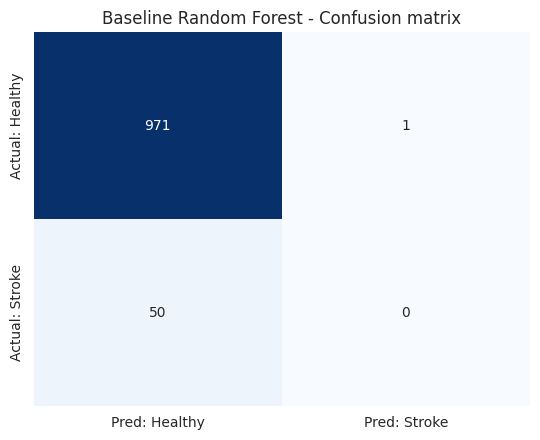

این نمودار نشان می‌دهد که مدل پایه تقریباً همه را «سالم» پیش‌بینی می‌کند؛ پس Accuracy بالاست ولی Recall نزدیک صفر است.

TN=971 (سالم و درست سالم) | FP=1 (سالم ولی هشدار) | FN=50 (بیمار نادیده‌مانده) | TP=0 (بیمار پیداشده)


In [17]:
rf_base = RandomForestClassifier(random_state=SEED, n_jobs=-1).fit(X_train_np, y_train)
p_rf_base = rf_base.predict_proba(X_test_np)[:, 1]
m, cm_base = evaluate("RF baseline", y_test, p_rf_base)
print("نتایج مدل پایه روی آزمون:")
for k, v in m.items(): print(f"  {k:10s}: {v:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_cm(ax, cm_base, "Baseline Random Forest - Confusion matrix")
save_show("09_confusion_baseline", "مدل پایه تقریباً همه را «سالم» پیش‌بینی می‌کند؛ پس Accuracy بالاست ولی Recall نزدیک صفر است.")
tn, fp, fn, tp = cm_base.ravel()
print(f"\nTN={tn} (سالم و درست سالم) | FP={fp} (سالم ولی هشدار) | FN={fn} (بیمار نادیده‌مانده) | TP={tp} (بیمار پیداشده)")

**پاسخ: چرا Accuracy بالاست ولی مدل بی‌فایده است؟ (توضیح برای مدیر بیمارستان)**

ماتریس چهار خانه دارد:
- **TN (بالا-چپ):** سالم بود و مدل هم «سالم» گفت - **FP (بالا-راست):** سالم بود ولی مدل اشتباهاً هشدار داد؛ هزینه‌اش یک معاینه‌ی اضافی است.
- **FN (پایین-چپ):** بیمار واقعی بود ولی مدل گفت سالم است؛ خطرناک‌ترین خانه، چون این بیمار دیر به درمان می‌رسد.
- **TP (پایین-راست):** بیمار بود و مدل او را پیدا کرد
حدود ۹۵٪ افراد سالم‌اند، پس مدلی که تقریباً همه را «سالم» اعلام کند Accuracy حدود ۹۵٪ می‌گیرد ولی عملاً هیچ بیماری را پیدا نمی‌کند (Recall ≈ ۰). مثل نگهبانی که هر شب بگوید «همه‌چیز امن است»: تقریباً همیشه درست می‌گوید، ولی شبی که دزد می‌آید هیچ فایده‌ای ندارد.

## فاز ۵ — طراحی الگوریتم از صفر (رگرسیون لجستیک با NumPy)
فقط NumPy برای خود مدل؛ scikit-learn فقط برای مقایسه‌ی نهایی.

1. برای هر بیمار یک امتیاز می‌سازیم: z = w₁·سن + w₂·فشارخون + … + b
2. سیگموید امتیاز را به احتمال تبدیل می‌کند: p = 1 / (1 + e^(−z))
3. تابع هزینه‌ی Cross-Entropy می‌گوید پیش‌بینی‌ها چقدر بد بوده‌اند.
4. گرادیان کاهشی وزن‌ها را قدم‌به‌قدم طوری عوض می‌کند که هزینه کم شود.
5. **نسخه‌ی وزن‌دار:** وزن نمونه‌ی بیمار بزرگ‌تر است (معکوس فراوانی کلاس) تا اشتباه روی بیمار گران‌تر تمام شود.

In [18]:
def sigmoid(z):
    z = np.clip(z, -500, 500)                    # جلوگیری از سرریز عددی
    return 1.0 / (1.0 + np.exp(-z))

def predict_proba_lr(X, w, b):
    return sigmoid(X @ w + b)                    # احتمال سکته برای هر سطر

def cross_entropy_cost(y, p, sample_w=None):
    eps = 1e-12
    p = np.clip(p, eps, 1 - eps)                 # جلوگیری از log(0)
    loss = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    if sample_w is None: sample_w = np.ones_like(loss)
    return np.sum(sample_w * loss) / len(y)

def balanced_sample_weights(y):
    # وزن معکوس فراوانی کلاس: n / (2 * تعداد کلاس) (همان فرمول 'balanced' در sklearn)
    n, n1 = len(y), y.sum(); n0 = n - n1
    return np.where(y == 1, n / (2 * n1), n / (2 * n0))

def train_logreg_gd(X, y, lr=0.1, n_iter=3000, sample_w=None):
    n, d = X.shape
    w, b = np.zeros(d), 0.0
    sw = np.ones(n) if sample_w is None else sample_w
    history = []
    for _ in range(n_iter):
        p = predict_proba_lr(X, w, b)                  # ۱) پیش‌بینی
        history.append(cross_entropy_cost(y, p, sw))   # ۲) هزینه
        err = (p - y) * sw                             # ۳) خطای هر نمونه × وزن آن نمونه
        w -= lr * (X.T @ err / n)                      # ۴) گرادیان وزن‌ها و قدم کوچک
        b -= lr * (err.sum() / n)                      #    گرادیان بایاس
    return w, b, history

print("sigmoid(0) =", sigmoid(0), "(باید ۰٫۵ باشد)")
print("sigmoid(10) =", round(float(sigmoid(10)), 5), "| sigmoid(-10) =", round(float(sigmoid(-10)), 5))

sigmoid(0) = 0.5 (باید ۰٫۵ باشد)
sigmoid(10) = 0.99995 | sigmoid(-10) = 5e-05


**۵-الف) اثر نرخ یادگیری**
پنج مقدار نرخ یادگیری (از بسیار کوچک تا بسیار بزرگ) را روی داده‌ی آموزش‌فرعی (با وزن‌دهی و ۱۰۰۰ تکرار) امتحان می‌کنیم و Recall را روی **اعتبارسنجی** می‌سنجیم (نه آزمون). ستون `cost_std_last100` نوسان هزینه در ۱۰۰ تکرار آخر و ستون `flagged_pct` درصد افرادی را نشان می‌دهد که مدل برایشان هشدار داده است.

وزن نمونه‌ی بیمار: 10.28 | وزن نمونه‌ی سالم: 0.53


,learning_rate,final_cost,val_Recall,val_Precision,cost_std_last100,flagged_pct
0,0.001,0.6239,1.000,0.1003,0.0014,48.7775
1,0.010,0.5085,0.950,0.1352,0.0010,34.3521
2,0.100,0.4818,0.900,0.1412,0.0000,31.1736
3,1.000,0.4802,0.875,0.1411,0.0000,30.3178
4,10.000,1.3258,1.000,0.0738,0.9188,66.2592


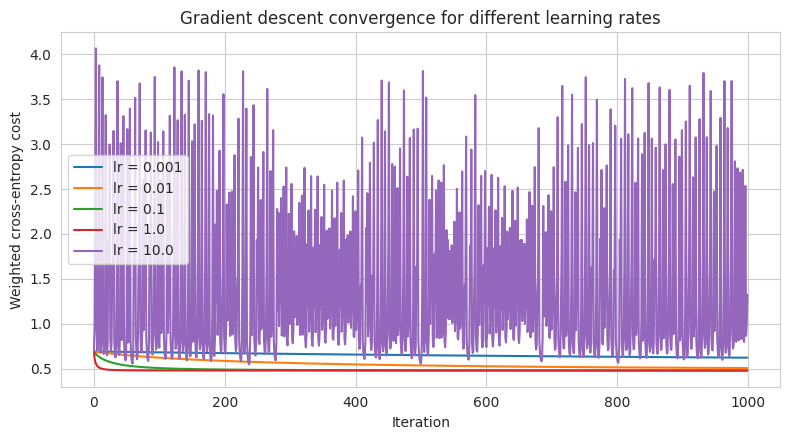

این نمودار نشان می‌دهد که نرخ یادگیری خیلی کوچک (۰٫۰۰۱) بسیار کند همگرا می‌شود، نرخ‌های ۰٫۱ و ۱ به‌خوبی همگرا می‌شوند و نرخ ۱۰ هزینه را نوسانی و ناپایدار می‌کند.


In [19]:
sw_tr = balanced_sample_weights(y_tr)
print(f"وزن نمونه‌ی بیمار: {sw_tr[y_tr==1][0]:.2f} | وزن نمونه‌ی سالم: {sw_tr[y_tr==0][0]:.2f}")

lr_list = [0.001, 0.01, 0.1, 1.0, 10.0]   # نرخ ۱۰ عمداً خیلی بزرگ است تا ناپایداری دیده شود
lr_histories, lr_rows = {}, []
for lr in lr_list:
    w_, b_, hist = train_logreg_gd(X_tr, y_tr, lr=lr, n_iter=1000, sample_w=sw_tr)
    lr_histories[lr] = hist
    mm, _ = evaluate("tmp", y_val, predict_proba_lr(X_val, w_, b_), store=False)
    lr_rows.append({"learning_rate": lr, "final_cost": hist[-1], "val_Recall": mm["Recall"], "val_Precision": mm["Precision"],
                    "cost_std_last100": float(np.std(hist[-100:])),          # نوسان هزینه در ۱۰۰ تکرار آخر
                    "flagged_pct": float((predict_proba_lr(X_val, w_, b_) >= 0.5).mean() * 100)})   # درصد افرادی که هشدار گرفتند
display(pd.DataFrame(lr_rows).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for lr, hist in lr_histories.items(): ax.plot(hist, label=f"lr = {lr}")
ax.set_title("Gradient descent convergence for different learning rates")
ax.set_xlabel("Iteration"); ax.set_ylabel("Weighted cross-entropy cost"); ax.legend()
save_show("10_learning_rate_comparison", "نرخ یادگیری خیلی کوچک (۰٫۰۰۱) بسیار کند همگرا می‌شود، نرخ‌های ۰٫۱ و ۱ به‌خوبی همگرا می‌شوند و نرخ ۱۰ هزینه را نوسانی و ناپایدار می‌کند.")

**پاسخ: نرخ یادگیری چه تأثیری داشت؟**
- **خیلی کوچک (۰٫۰۰۱):** مدل دچار Underfitting شد. قدم‌ها آن‌قدر ریزند که در ۱۰۰۰ تکرار هزینه فقط تا حدود ۰٫۶۲ پایین آمد (در حالی که برای نرخ‌های بزرگ‌تر حدود ۰٫۴۸ شد). Recall برابر ۱ ظاهراً عالی است، ولی فریبنده است: Precision فقط حدود ۰٫۱۰ است، یعنی حدود نیمی از افراد اعتبارسنجی هشدار گرفته‌اند. مدل هنوز چیزی یاد نگرفته و تقریباً برای همه هشدار می‌دهد.
- **متوسط تا بزرگ (۰٫۰۱ تا ۱):** هزینه سریع‌تر پایین می‌آید و در انتها صاف می‌شود. برای ۰٫۱ و ۱ تقریباً به یک مقدار می‌رسند، یعنی همگرایی کامل شده است.
- **خیلی بزرگ (۱۰):** قدم‌ها از کف دره رد می‌شوند و هزینه به‌جای کاهش نوسان می‌کند و به مقدار پایین پایدار نمی‌رسد (ستون `cost_std_last100` برای آن بزرگ‌تر از بقیه است). این همان نشانه‌ای است که صورت پروژه برای نرخ یادگیری بزرگ گفته است.

نرخ مناسب جایی است که منحنی سریع نزولی و در انتها صاف باشد؛ به همین دلیل در آموزش نهایی `lr=1.0` با ۵۰۰۰ تکرار به کار رفته است.

**۵-ب) آموزش نهایی: نسخه‌ی بدون وزن و نسخه‌ی وزن‌دار (روی کل داده‌ی آموزش)**

,Accuracy,Precision,Recall,F1,AUC,PR_AUC
scratch (no weight),0.952,1.000,0.02,0.039,0.839,0.273
scratch (weighted),0.739,0.135,0.80,0.231,0.840,0.260


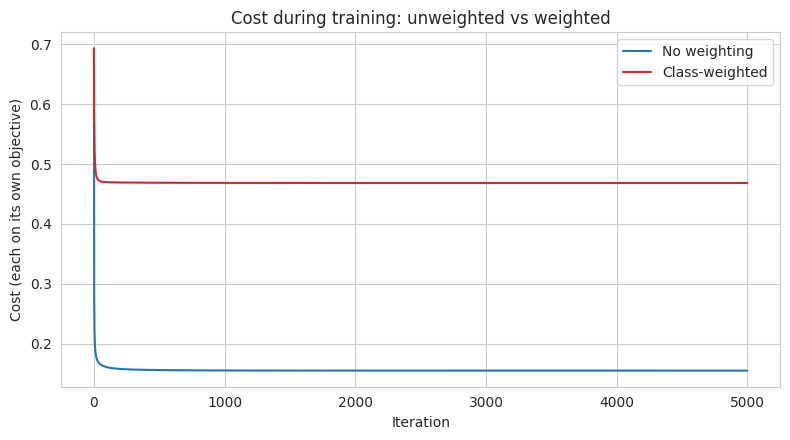

این نمودار نشان می‌دهد که هر دو منحنی نزولی و در انتها صاف‌اند و هزینه‌ی نسخه‌ی وزن‌دار بالاتر است چون خطای بیماران گران‌تر حساب می‌شود.


In [20]:
LR_FINAL, N_ITER = 1.0, 5000
sw_train = balanced_sample_weights(y_train)

w_plain, b_plain, h_plain = train_logreg_gd(X_train_np, y_train, lr=LR_FINAL, n_iter=N_ITER)
w_wtd,   b_wtd,   h_wtd   = train_logreg_gd(X_train_np, y_train, lr=LR_FINAL, n_iter=N_ITER, sample_w=sw_train)

m1, cm_plain = evaluate("LogReg scratch (no weight)", y_test, predict_proba_lr(X_test_np, w_plain, b_plain))
m2, cm_wtd   = evaluate("LogReg scratch (weighted)",  y_test, predict_proba_lr(X_test_np, w_wtd, b_wtd))
display(pd.DataFrame([m1, m2], index=["scratch (no weight)", "scratch (weighted)"]).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(h_plain, label="No weighting", color=COL_HEALTHY); ax.plot(h_wtd, label="Class-weighted", color=COL_PATIENT)
ax.set_title("Cost during training: unweighted vs weighted")
ax.set_xlabel("Iteration"); ax.set_ylabel("Cost (each on its own objective)"); ax.legend()
save_show("11_weighted_vs_unweighted_cost", "هر دو منحنی نزولی و در انتها صاف‌اند و هزینه‌ی نسخه‌ی وزن‌دار بالاتر است چون خطای بیماران گران‌تر حساب می‌شود.")

**پاسخ: وزن‌دهی دقیقاً چه تغییری در گرادیان ایجاد می‌کند؟**
در حالت عادی گرادیان هر نمونه (p − y)·x است و میانگین گرفته می‌شود. در حالت وزن‌دار هر نمونه در وزنش ضرب می‌شود: wᵢ·(pᵢ − yᵢ)·xᵢ. وزن نمونه‌ی بیمار حدود ۱۰ برابر نمونه‌ی سالم است، پس سهم بیماران در گرادیان بزرگ می‌شود و وزن‌های مدل به سمتی کشیده می‌شوند که بیماران را بهتر پیدا کند. در کد تنها تفاوت خط `err = (p - y) * sw` است. نتیجه: مدل دیگر نمی‌تواند با «همه را سالم گفتن» هزینه را کم کند.

**۵-پ) مقایسه با `LogisticRegression(class_weight='balanced')`**

,Accuracy,Precision,Recall,F1,AUC,PR_AUC
scratch (weighted),0.739,0.135,0.8,0.231,0.84,0.26
sklearn balanced,0.739,0.135,0.8,0.231,0.84,0.26


,feature,scratch,sklearn,abs_diff
0,age,1.902,1.900,0.002
1,hypertension,0.633,0.634,0.002
2,heart_disease,0.141,0.147,0.007
3,avg_glucose_level,0.211,0.211,0.000
4,bmi,0.063,0.063,0.001
5,gender_Male,-0.137,-0.138,0.001
6,ever_married_Yes,-0.169,-0.168,0.001
7,work_type_Never_worked,-0.256,-0.090,0.166
8,work_type_Private,0.031,0.035,0.004
9,work_type_Self-employed,-0.210,-0.202,0.007


بیشترین اختلاف ضرایب: 0.166
اختلاف بایاس: 0.0031


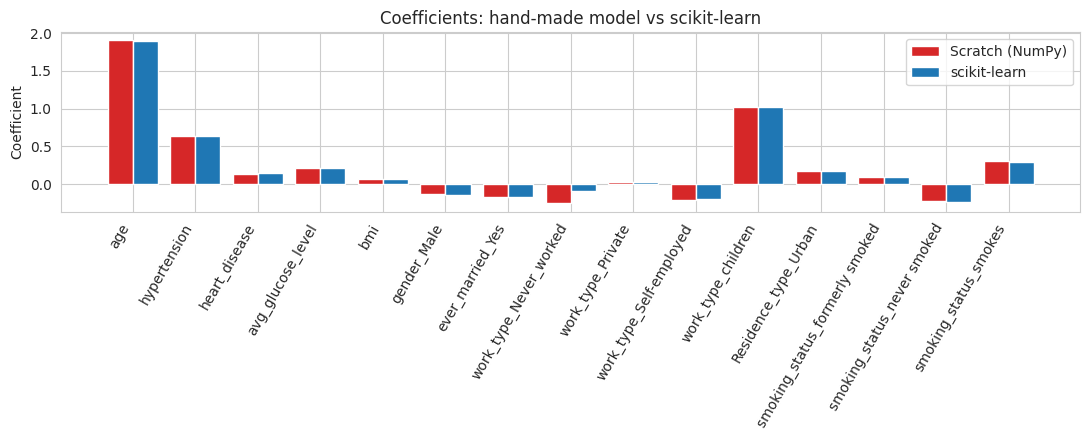

این نمودار نشان می‌دهد که ضرایب مدل دست‌ساز تقریباً با scikit-learn برابر است؛ یعنی پیاده‌سازی درست است.


In [21]:
# C بسیار بزرگ یعنی تقریباً بدون منظم‌سازی، تا با مدل دست‌ساز (بدون منظم‌سازی) قابل مقایسه باشد
sk_lr = LogisticRegression(class_weight="balanced", C=1e6, max_iter=10000).fit(X_train_np, y_train)
m3, cm_sk = evaluate("sklearn LogReg balanced", y_test, sk_lr.predict_proba(X_test_np)[:, 1])
display(pd.DataFrame([m2, m3], index=["scratch (weighted)", "sklearn balanced"]).round(3))

coef_df = pd.DataFrame({"feature": feature_names, "scratch": w_wtd, "sklearn": sk_lr.coef_.ravel()})
coef_df["abs_diff"] = (coef_df["scratch"] - coef_df["sklearn"]).abs()
display(coef_df.round(3))
print("بیشترین اختلاف ضرایب:", round(float(coef_df["abs_diff"].max()), 4))
print("اختلاف بایاس:", round(float(abs(b_wtd - sk_lr.intercept_[0])), 4))

idx = np.arange(len(feature_names)); wd = 0.4
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(idx - wd/2, coef_df["scratch"], wd, label="Scratch (NumPy)", color=COL_PATIENT)
ax.bar(idx + wd/2, coef_df["sklearn"], wd, label="scikit-learn", color=COL_HEALTHY)
ax.set_xticks(idx); ax.set_xticklabels(feature_names, rotation=60, ha="right")
ax.set_title("Coefficients: hand-made model vs scikit-learn"); ax.set_ylabel("Coefficient"); ax.legend()
save_show("12_coefficients_scratch_vs_sklearn", "ضرایب مدل دست‌ساز تقریباً با scikit-learn برابر است؛ یعنی پیاده‌سازی درست است.")

**پاسخ: نتیجه‌ی مدل شما با scikit-learn چقدر فرق دارد و چرا؟**
معیارهای ارزیابی روی آزمون کاملاً یکسان‌اند (AUC=۰٫۸۴، Recall=۰٫۸۰) و ضرایب تقریباً برابرند. بیشترین اختلاف در بقیه‌ی ضرایب ۰٫۰۰۷ است و این یعنی پیاده‌سازی درست است. اختلاف‌های ناچیز به این دلیل است که scikit-learn با بهینه‌ساز `lbfgs` دقیق‌تر همگرا می‌شود، ولی گرادیان کاهشی ساده‌ی ما تعداد تکرار ثابت (۵۰۰۰) دارد.

تنها استثنا ضریب `work_type_Never_worked` است (۰٫۲۵۶- در مدل ما و ۰٫۰۹۰- در scikit-learn). دلیل آن این است که در این ستون فقط حدود ۲۲ نفر در کل داده هستند و هیچ‌کدام سکته نکرده‌اند (در آموزش حتی کمتر). وقتی یک ویژگی کاملاً با یک کلاس همراه باشد، بهینه‌سازی بدون منظم‌سازی ضریب را مدام منفی‌تر می‌کند و مقدار نهایی به نقطه‌ی توقف الگوریتم بستگی دارد، نه به یک جواب یکتا. پس این اختلاف خطای پیاده‌سازی نیست و تأثیری هم روی پیش‌بینی ندارد، چون ویژگی بسیار کم‌تکرار است.

**۵-ت) پراکندگی سن در برابر قند خون (شهود هندسی — اختیاری)**

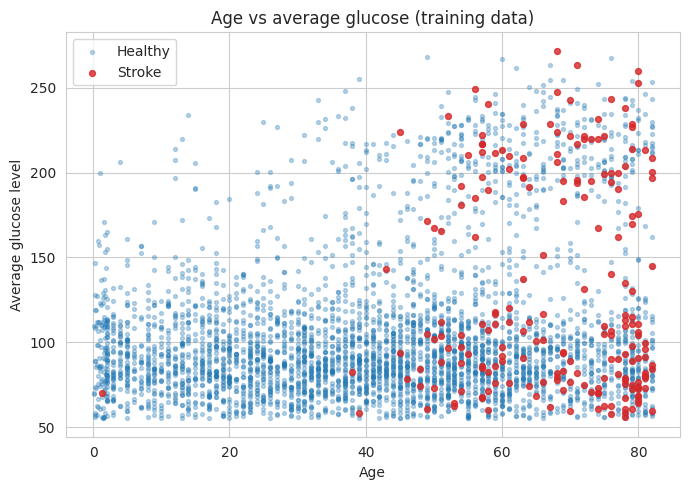

این نمودار نشان می‌دهد که بیماران بیشتر در سن و قند خون بالا جمع شده‌اند ولی با سالم‌ها همپوشانی زیادی دارند؛ پس جداسازی کامل ممکن نیست.


In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
h = raw_train[raw_train["stroke"] == 0]; s = raw_train[raw_train["stroke"] == 1]
ax.scatter(h["age"], h["avg_glucose_level"], s=8, alpha=0.3, color=COL_HEALTHY, label="Healthy")
ax.scatter(s["age"], s["avg_glucose_level"], s=18, alpha=0.8, color=COL_PATIENT, label="Stroke")
ax.set_title("Age vs average glucose (training data)"); ax.set_xlabel("Age"); ax.set_ylabel("Average glucose level"); ax.legend()
save_show("13_scatter_age_glucose", "بیماران بیشتر در سن و قند خون بالا جمع شده‌اند ولی با سالم‌ها همپوشانی زیادی دارند؛ پس جداسازی کامل ممکن نیست.")

**۵-ث) بخش اختیاری: SMOTE ساده از صفر**
یک نمونه‌ی بیمار انتخاب می‌شود، k همسایه‌ی نزدیکش (از بین بیماران) پیدا می‌شود، یکی از آن‌ها انتخاب می‌شود و نقطه‌ی جدید روی خط بین آن دو ساخته می‌شود: نقطه‌ی جدید = نمونه + λ × (همسایه − نمونه)، با λ تصادفی بین ۰ و ۱.

In [23]:
def smote_scratch(X_min, n_new, k=5, seed=SEED):
    rng = np.random.default_rng(seed)
    synthetic = []
    for _ in range(n_new):
        i = rng.integers(len(X_min))                              # ۱) یک بیمار تصادفی
        dists = np.linalg.norm(X_min - X_min[i], axis=1)          # ۲) فاصله تا همه‌ی بیماران
        neighbors = np.argsort(dists)[1:k+1]                      #    k نزدیک‌ترین (به‌جز خودش)
        j = rng.choice(neighbors)                                 # ۳) یک همسایه‌ی تصادفی
        lam = rng.random()                                        # ۴) عدد تصادفی بین ۰ و ۱
        synthetic.append(X_min[i] + lam * (X_min[j] - X_min[i]))  # ۵) نقطه‌ی جدید روی خط
    return np.array(synthetic)

X_min = X_train_np[y_train == 1]
n_new = int((y_train == 0).sum() - (y_train == 1).sum())
X_syn = smote_scratch(X_min, n_new)
X_sm = np.vstack([X_train_np, X_syn]); y_sm = np.concatenate([y_train, np.ones(n_new, dtype=int)])
print(f"قبل: بیمار={int(y_train.sum())}, سالم={int((y_train==0).sum())}")
print(f"بعد: بیمار={int(y_sm.sum())}, سالم={int((y_sm==0).sum())}")

w_s, b_s, _ = train_logreg_gd(X_sm, y_sm, lr=LR_FINAL, n_iter=N_ITER)
m_s, _ = evaluate("LogReg scratch + SMOTE scratch", y_test, predict_proba_lr(X_test_np, w_s, b_s))
print("\nنتیجه‌ی لجستیک دست‌ساز + SMOTE دست‌ساز روی آزمون:", {k: round(v, 3) for k, v in m_s.items()})

قبل: بیمار=199, سالم=3888
بعد: بیمار=3888, سالم=3888

نتیجه‌ی لجستیک دست‌ساز + SMOTE دست‌ساز روی آزمون: {'Accuracy': 0.736, 'Precision': 0.133, 'Recall': 0.8, 'F1': 0.229, 'AUC': 0.839, 'PR_AUC': 0.287}


## فاز ۶ — مقابله با عدم توازن
سه روش روی Random Forest:
1. `class_weight='balanced'`: خطای بیماران را گران‌تر می‌کند.
2. **SMOTE:** با ساختن بیماران مصنوعی دو کلاس را برابر می‌کند (فقط روی آموزش).
3. **Undersampling:** تعداد سالم‌ها را تصادفی کم می‌کند (فقط روی آموزش).

,Original train,After SMOTE,After Undersampling
Healthy,3888,3888,199
Stroke,199,3888,199


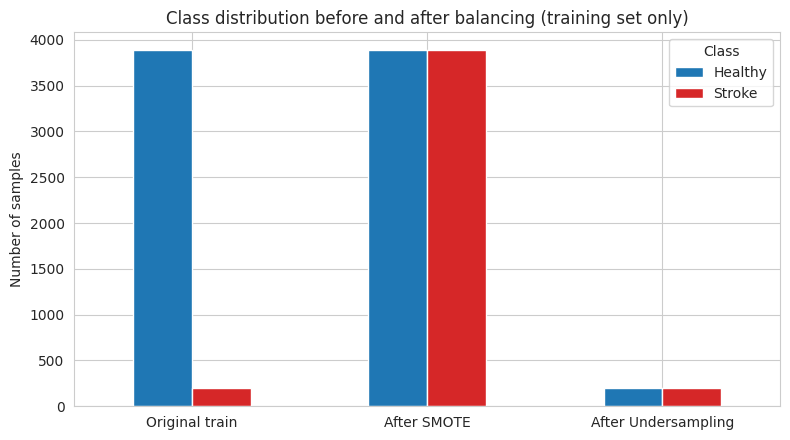

این نمودار نشان می‌دهد که SMOTE تعداد بیماران را بالا می‌برد و Undersampling تعداد سالم‌ها را پایین می‌آورد؛ در هر دو حالت کلاس‌ها برابر می‌شوند.


In [24]:
rf_bal = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1).fit(X_train_np, y_train)
evaluate("RF balanced", y_test, rf_bal.predict_proba(X_test_np)[:, 1])

X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_train_np, y_train)        # فقط روی آموزش
rf_smote = RandomForestClassifier(random_state=SEED, n_jobs=-1).fit(X_smote, y_smote)
evaluate("RF SMOTE", y_test, rf_smote.predict_proba(X_test_np)[:, 1])

X_under, y_under = RandomUnderSampler(random_state=SEED).fit_resample(X_train_np, y_train)   # فقط روی آموزش
rf_under = RandomForestClassifier(random_state=SEED, n_jobs=-1).fit(X_under, y_under)
evaluate("RF Undersample", y_test, rf_under.predict_proba(X_test_np)[:, 1])

dist = pd.DataFrame({"Original train": [int((y_train == 0).sum()), int((y_train == 1).sum())],
                     "After SMOTE": [int((y_smote == 0).sum()), int((y_smote == 1).sum())],
                     "After Undersampling": [int((y_under == 0).sum()), int((y_under == 1).sum())]}, index=["Healthy", "Stroke"])
display(dist)
ax = dist.T.plot(kind="bar", color=[COL_HEALTHY, COL_PATIENT], figsize=(8, 4.5), rot=0)
plt.title("Class distribution before and after balancing (training set only)")
plt.ylabel("Number of samples"); plt.legend(title="Class")
save_show("14_class_distribution_balancing", "SMOTE تعداد بیماران را بالا می‌برد و Undersampling تعداد سالم‌ها را پایین می‌آورد؛ در هر دو حالت کلاس‌ها برابر می‌شوند.")

,Accuracy,Precision,Recall,F1,AUC
RF baseline,0.950,0.000,0.00,0.000,0.791
RF balanced,0.950,0.000,0.00,0.000,0.781
RF SMOTE,0.934,0.207,0.12,0.152,0.763
RF Undersample,0.659,0.106,0.80,0.187,0.806


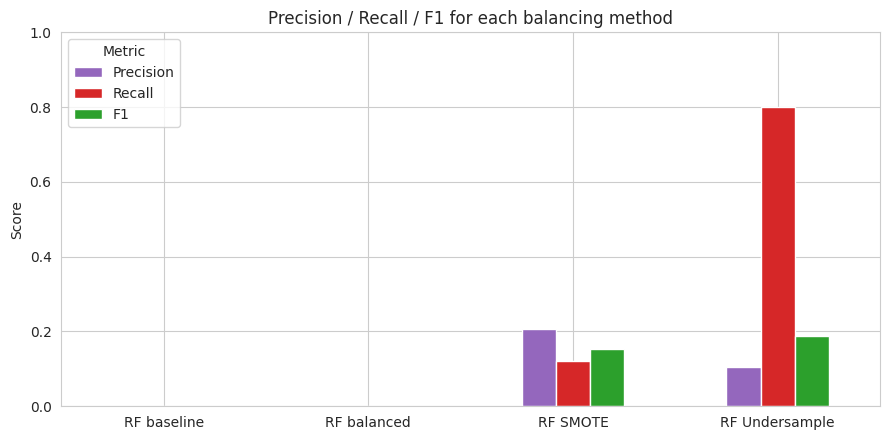

این نمودار نشان می‌دهد که فقط Undersampling توانست Recall بالایی بدهد و آن هم به قیمت Precision بسیار پایین؛ class_weight و SMOTE روی Random Forest تقریباً کمکی نکردند.


In [25]:
rf_methods = ["RF baseline", "RF balanced", "RF SMOTE", "RF Undersample"]
table6 = pd.DataFrame(results).T.loc[rf_methods, ["Accuracy", "Precision", "Recall", "F1", "AUC"]].round(3)
display(table6)
table6[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#9467bd", COL_PATIENT, "#2ca02c"])
plt.title("Precision / Recall / F1 for each balancing method")
plt.ylabel("Score"); plt.ylim(0, 1); plt.legend(title="Metric")
save_show("15_balancing_methods_comparison", "فقط Undersampling توانست Recall بالایی بدهد و آن هم به قیمت Precision بسیار پایین؛ class_weight و SMOTE روی Random Forest تقریباً کمکی نکردند.")

**پاسخ: کدام روش Recall بهتری داد؟ در ازای آن چه چیزی از دست رفت؟**
**Undersampling** بالاترین Recall را داد (حدود ۰٫۸۰ در برابر ۰ برای مدل پایه). بهای آن Precision بسیار پایین (حدود ۰٫۱۱) و افت شدید Accuracy (حدود ۰٫۶۶) است: مدل سالم‌های زیادی را «بیمار» اعلام می‌کند و ما بخش بزرگی از داده‌ی سالم را دور ریخته‌ایم (اطلاعات از دست رفته). روش SMOTE فقط Recall اندکی ایجاد کرد (حدود ۰٫۱۲) و `class_weight` در Random Forest اثری نداشت (Recall = ۰). دلیل: درخت‌های عمیق داده‌ی آموزش را تقریباً حفظ می‌کنند و برگ‌هایشان خالص می‌شود، پس وزن‌دهی یا نمونه‌ی مصنوعی روی احتمال‌های خروجی اثر کمی دارد و با آستانه‌ی ۰٫۵ هنوز بیمار پیش‌بینی نمی‌شود.

## فاز ۷ — شبکه‌ی عمیق با Keras
شبکه‌ی Dense با لایه‌های مخفی `relu`، لایه‌ی Dropout (خاموش‌کردن تصادفی بخشی از نرون‌ها برای جلوگیری از حفظ‌کردن) و خروجی سیگموید.
- **عدم توازن:** `class_weight`.
- **اعتبارسنجی:** همان `X_val` که در فاز ۳ از آموزش جدا شد؛ آزمون دست‌نخورده است.
- **EarlyStopping** روی `val_auc` (چون `val_loss` با داده‌ی نامتوازن گمراه‌کننده است) و بازگرداندن بهترین وزن‌ها.
- دو معماری مقایسه می‌شوند.

In [26]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
tf.keras.utils.set_random_seed(SEED)

Xtr32, Xval32 = X_tr.astype("float32"), X_val.astype("float32")
ytr32, yval32 = y_tr.astype("float32"), y_val.astype("float32")
n_tr, n1_tr = len(ytr32), ytr32.sum()
class_weight = {0: float(n_tr / (2 * (n_tr - n1_tr))), 1: float(n_tr / (2 * n1_tr))}
print("وزن کلاس‌ها:", {k: round(v, 2) for k, v in class_weight.items()})

def build_model(units, dropout, lr):
    model = keras.Sequential([layers.Input(shape=(Xtr32.shape[1],))])
    for u in units:
        model.add(layers.Dense(u, activation="relu")); model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")])
    return model

configs = {"DNN-A": dict(units=[32, 16], dropout=0.3, lr=1e-3),
           "DNN-B": dict(units=[128, 64, 32], dropout=0.5, lr=5e-4)}
histories, dnn_models = {}, {}
for name, cfg in configs.items():
    print(f"\n=== آموزش {name} با تنظیمات {cfg} ===")
    model = build_model(**cfg)
    es = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=20, restore_best_weights=True)
    hist = model.fit(Xtr32, ytr32, validation_data=(Xval32, yval32), epochs=200, batch_size=64,
                     class_weight=class_weight, callbacks=[es], verbose=0)
    histories[name], dnn_models[name] = hist, model
    best_epoch = int(np.argmax(hist.history["val_auc"])) + 1
    print(f"epoch اجراشده: {len(hist.history['loss'])} | بهترین epoch: {best_epoch} | بهترین val_auc: {max(hist.history['val_auc']):.3f}")
    mm, _ = evaluate(name, y_test, model.predict(X_test_np.astype("float32"), verbose=0).ravel())
    print("نتیجه روی آزمون:", {k: round(v, 3) for k, v in mm.items()})

وزن کلاس‌ها: {0: 0.53, 1: 10.28}

=== آموزش DNN-A با تنظیمات {'units': [32, 16], 'dropout': 0.3, 'lr': 0.001} ===
epoch اجراشده: 25 | بهترین epoch: 5 | بهترین val_auc: 0.897
نتیجه روی آزمون: {'Accuracy': 0.679, 'Precision': 0.114, 'Recall': 0.82, 'F1': 0.2, 'AUC': 0.816, 'PR_AUC': 0.192}

=== آموزش DNN-B با تنظیمات {'units': [128, 64, 32], 'dropout': 0.5, 'lr': 0.0005} ===
epoch اجراشده: 26 | بهترین epoch: 6 | بهترین val_auc: 0.893
نتیجه روی آزمون: {'Accuracy': 0.657, 'Precision': 0.109, 'Recall': 0.84, 'F1': 0.193, 'AUC': 0.829, 'PR_AUC': 0.199}


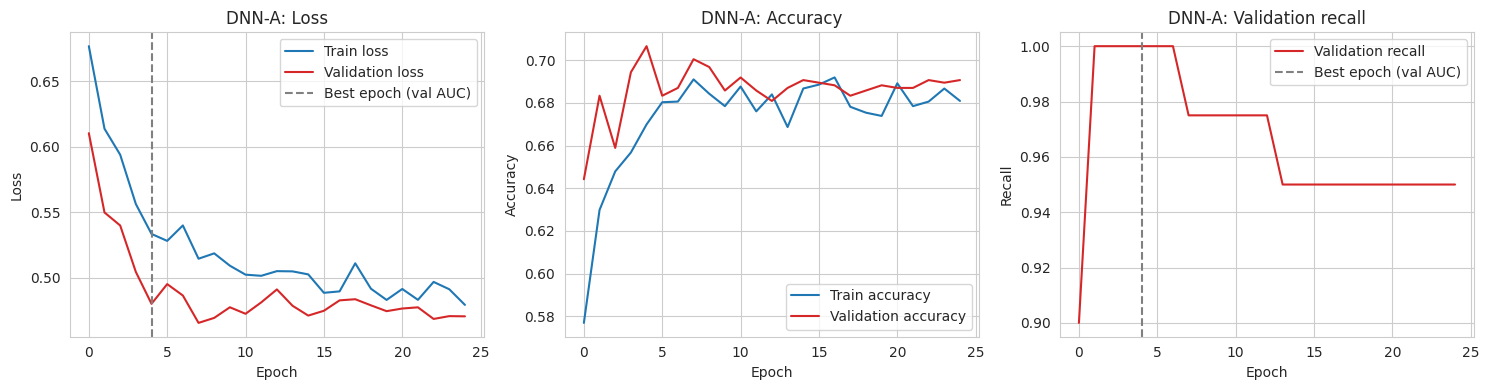

این نمودار نشان می‌دهد که خطا و دقت آموزش و اعتبارسنجی را مقایسه می‌کند و خط خاکستری بهترین epoch را (نقطه‌ی توقف) نشان می‌دهد.
DNN-A: خطای آموزش در بهترین epoch=0.533 → در آخرین epoch=0.479 | خطای اعتبارسنجی در بهترین epoch=0.480 → در آخرین epoch=0.471


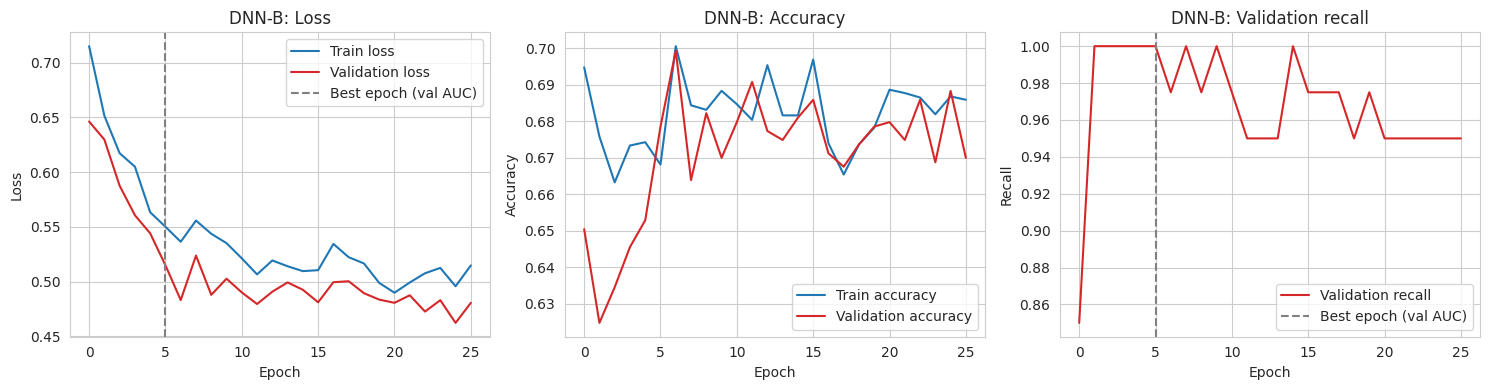

این نمودار نشان می‌دهد که خطا و دقت آموزش و اعتبارسنجی را مقایسه می‌کند و خط خاکستری بهترین epoch را (نقطه‌ی توقف) نشان می‌دهد.
DNN-B: خطای آموزش در بهترین epoch=0.550 → در آخرین epoch=0.515 | خطای اعتبارسنجی در بهترین epoch=0.515 → در آخرین epoch=0.481


In [27]:
def plot_history(hist, name, fname):
    h = hist.history; best = int(np.argmax(h["val_auc"]))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(h["loss"], label="Train loss", color=COL_HEALTHY); axes[0].plot(h["val_loss"], label="Validation loss", color=COL_PATIENT)
    axes[0].axvline(best, color="gray", linestyle="--", label="Best epoch (val AUC)")
    axes[0].set_title(f"{name}: Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].plot(h["accuracy"], label="Train accuracy", color=COL_HEALTHY); axes[1].plot(h["val_accuracy"], label="Validation accuracy", color=COL_PATIENT)
    axes[1].set_title(f"{name}: Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    axes[2].plot(h["val_recall"], label="Validation recall", color=COL_PATIENT)
    axes[2].axvline(best, color="gray", linestyle="--", label="Best epoch (val AUC)")
    axes[2].set_title(f"{name}: Validation recall"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Recall"); axes[2].legend()
    save_show(fname, "خطا و دقت آموزش و اعتبارسنجی را مقایسه می‌کند و خط خاکستری بهترین epoch را (نقطه‌ی توقف) نشان می‌دهد.")
    print(f"{name}: خطای آموزش در بهترین epoch={h['loss'][best]:.3f} → در آخرین epoch={h['loss'][-1]:.3f} | "
          f"خطای اعتبارسنجی در بهترین epoch={h['val_loss'][best]:.3f} → در آخرین epoch={h['val_loss'][-1]:.3f}")

plot_history(histories["DNN-A"], "DNN-A", "16_dnn_A_history")
plot_history(histories["DNN-B"], "DNN-B", "17_dnn_B_history")

**پاسخ: آیا Overfitting رخ داد؟ از کجای نمودار فهمیدید؟**
Overfitting واضحی دیده نشد. بهترین epoch در DNN-A برابر ۵ و در DNN-B برابر ۶ بود و `val_auc` بعد از آن بهتر نشد (حدود ۰٫۹۰ و ۰٫۸۹)، پس `EarlyStopping` پس از ۲۰ epoch صبر آموزش را متوقف کرد و بهترین وزن‌ها را برگرداند. خطای اعتبارسنجی بالا نرفت: در DNN-A از ۰٫۴۸۰ به ۰٫۴۷۱ و در DNN-B از ۰٫۵۱۵ به ۰٫۴۸۱ رسید. آنچه دیده می‌شود فقط **توقف زودهنگام پیشرفت** است، نه حفظ‌کردن داده.

*دو نکته‌ی احتیاط:*
۱) خطای آموزش با `class_weight` وزن‌دار حساب می‌شود ولی خطای اعتبارسنجی بدون وزن است؛ پس مقایسه‌ی مستقیم این دو منحنی دقیق نیست.
۲) مجموعه‌ی اعتبارسنجی فقط حدود ۴۰ بیمار دارد و `val_auc` (حدود ۰٫۹) خوش‌بینانه‌تر از AUC آزمون (۰٫۸۲ تا ۰٫۸۳) و نویزی است.

**پاسخ: آیا شبکه‌ی عمیق از Random Forest بهتر بود؟ چرا؟**
نسبت به Random Forest **پایه** بله: DNN-B به AUC=۰٫۸۳ و Recall=۰٫۸۴ رسید، در حالی که RF پایه AUC=۰٫۷۹ و Recall=۰ داشت (بخشی از این برتری به `class_weight` شبکه برمی‌گردد). نسبت به RF با Undersampling (AUC=۰٫۸۱ و Recall=۰٫۸۰) فقط اختلاف کمی دارد و به رگرسیون لجستیک وزن‌دار (AUC=۰٫۸۴) هم برتری ندارد. دلیل‌ها: ۱) داده‌ی جدولی و کوچک است (فقط ۱۹۹ بیمار در آموزش) و شبکه‌ی عمیق برای داده‌ی بزرگ مناسب‌تر است؛ ۲) رابطه‌ی ویژگی‌ها با سکته، به‌ویژه سن، ساده و تقریباً خطی است، پس مدل ساده کافی است.

## فاز ۸ — ارزیابی نهایی و تفسیر
**اصل روش‌شناسی:** مجموعه‌ی آزمون فقط برای *گزارش* نتیجه‌ی مدل‌ها استفاده می‌شود. مدل نهایی و آستانه‌ی تصمیم‌گیری **بدون استفاده از آزمون** و با پیش‌بینی‌های اعتبارسنجی متقاطع ۵-تکه روی داده‌ی آموزش انتخاب می‌شوند.

In [28]:
final_table = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1", "AUC", "PR_AUC"]].round(3).sort_values("PR_AUC", ascending=False)
display(final_table)
palette10 = plt.cm.tab10.colors
model_colors = {name: palette10[i % 10] for i, name in enumerate(results.keys())}

,Accuracy,Precision,Recall,F1,AUC,PR_AUC
LogReg scratch + SMOTE scratch,0.736,0.133,0.80,0.229,0.839,0.287
LogReg scratch (no weight),0.952,1.000,0.02,0.039,0.839,0.273
sklearn LogReg balanced,0.739,0.135,0.80,0.231,0.840,0.260
LogReg scratch (weighted),0.739,0.135,0.80,0.231,0.840,0.260
DNN-B,0.657,0.109,0.84,0.193,0.829,0.199
DNN-A,0.679,0.114,0.82,0.200,0.816,0.192
RF Undersample,0.659,0.106,0.80,0.187,0.806,0.162
RF baseline,0.950,0.000,0.00,0.000,0.791,0.150
RF SMOTE,0.934,0.207,0.12,0.152,0.763,0.134
RF balanced,0.950,0.000,0.00,0.000,0.781,0.132


نکته: مدل‌هایی که Recall نزدیک صفر دارند (مثل لجستیک بدون وزن) ممکن است PR_AUC بالایی داشته باشند ولی با آستانه‌ی ۰٫۵ هیچ بیماری را پیدا نمی‌کنند. PR_AUC فقط توان رتبه‌بندی را می‌سنجد و عملکرد در آستانه‌ی کاری را نشان نمی‌دهد؛ پس انتخاب نهایی باید Recall را هم در نظر بگیرد.

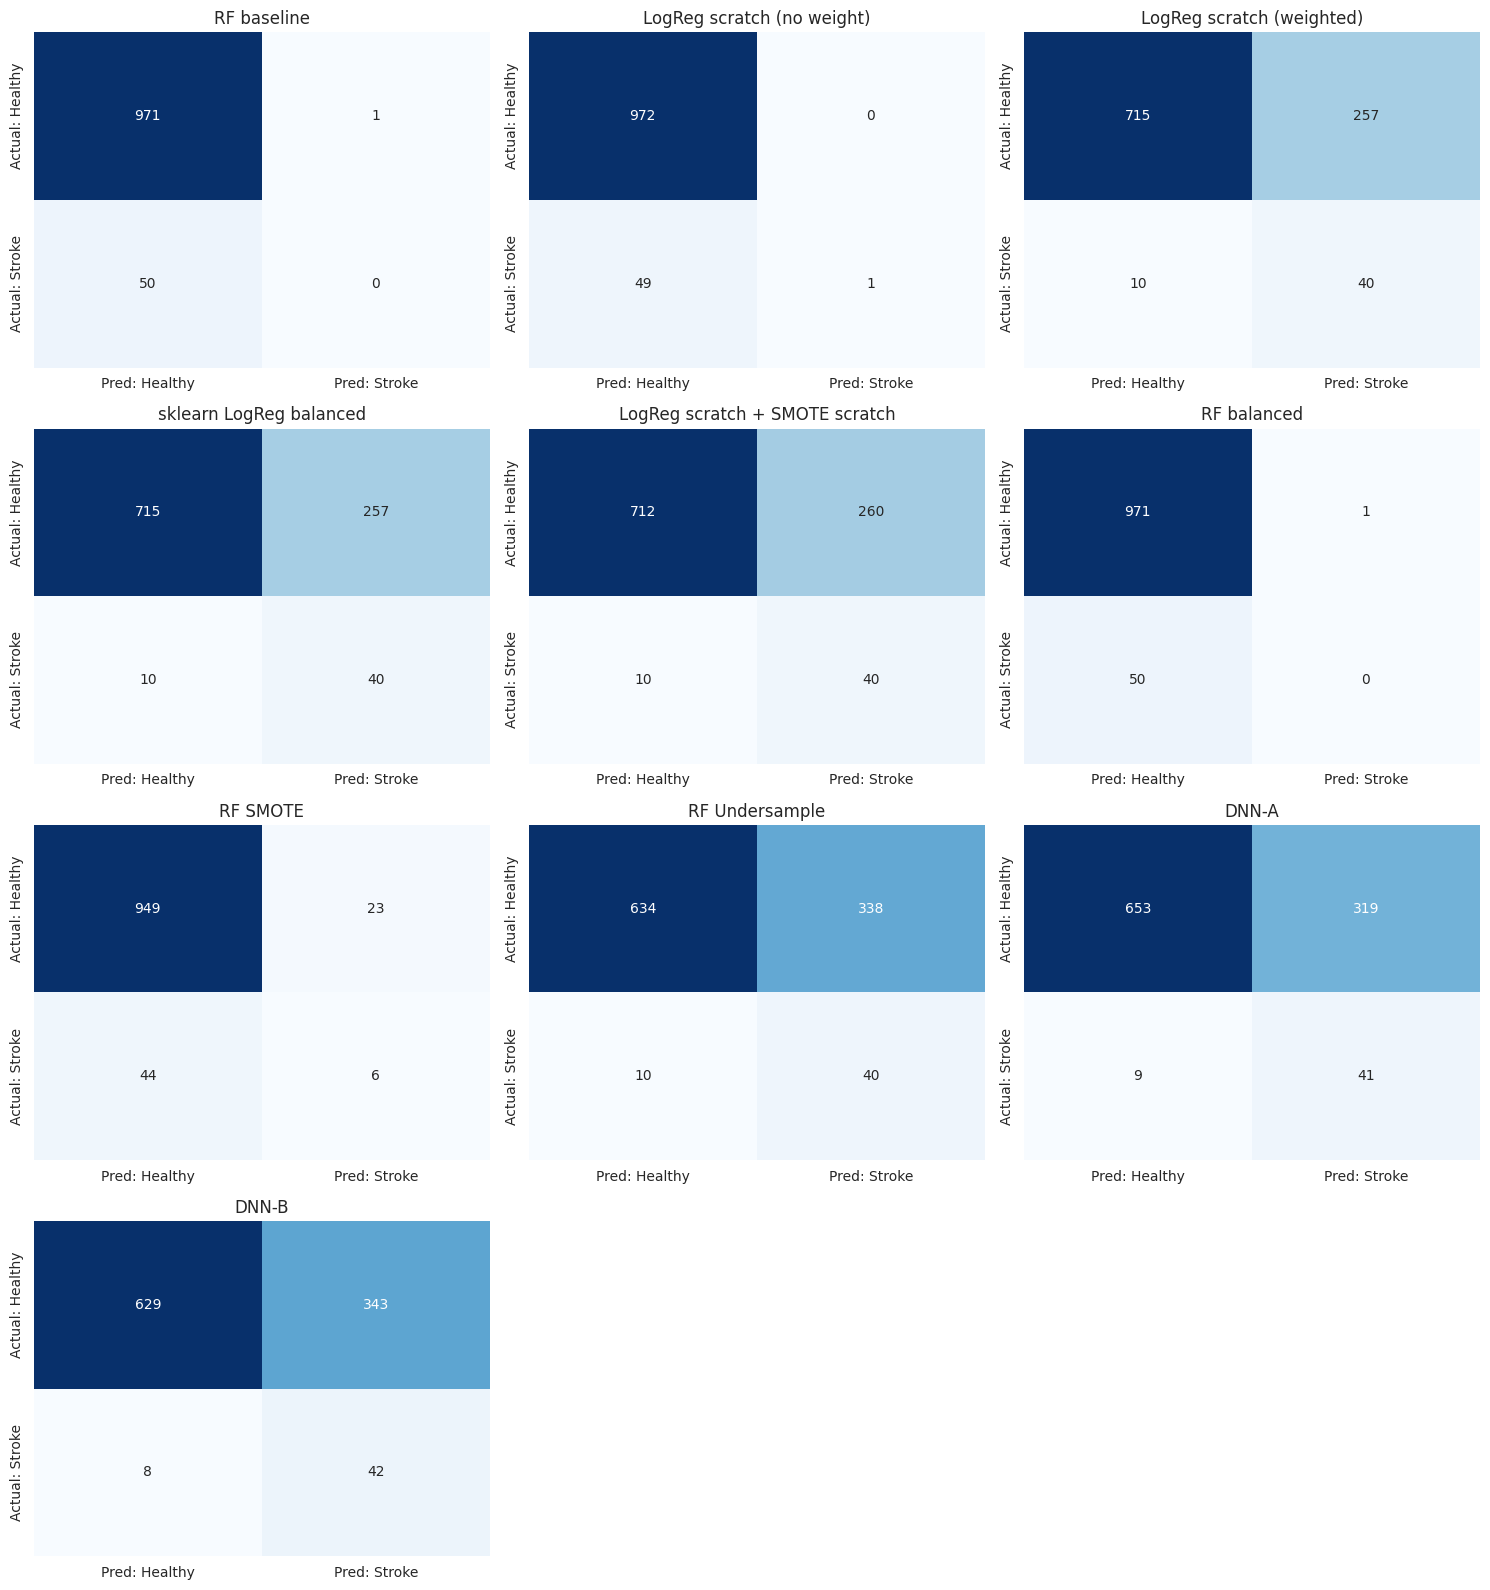

این نمودار نشان می‌دهد که مدل‌های وزن‌دار یا Undersample بیماران بیشتری پیدا می‌کنند (خانه‌ی پایین-راست) به قیمت هشدار اشتباه بیشتر (بالا-راست).


In [29]:
names = list(results.keys())
ncols = 3; nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows)); axes = np.array(axes).ravel()
for ax, nm in zip(axes, names):
    plot_cm(ax, confusion_matrix(y_test, (proba_dict[nm] >= 0.5).astype(int)), nm)
for ax in axes[len(names):]: ax.axis("off")
save_show("18_all_confusion_matrices", "مدل‌های وزن‌دار یا Undersample بیماران بیشتری پیدا می‌کنند (خانه‌ی پایین-راست) به قیمت هشدار اشتباه بیشتر (بالا-راست).")

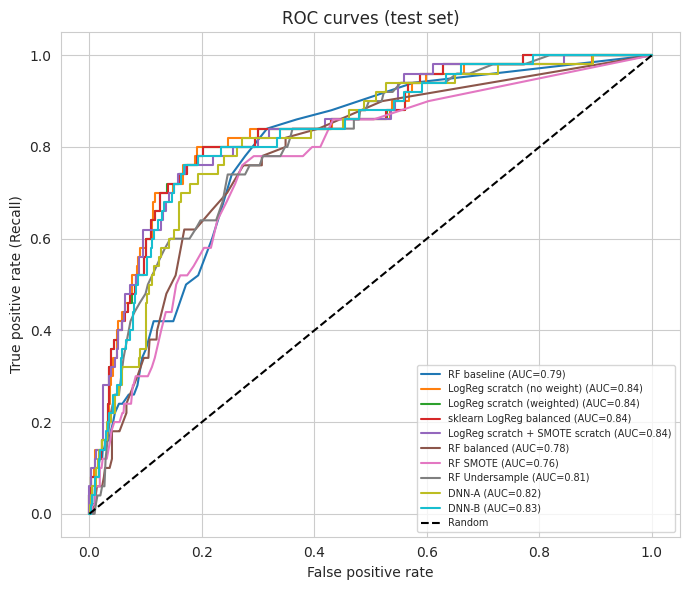

این نمودار نشان می‌دهد که مدل‌های لجستیک و شبکه‌ی عصبی توان تفکیک (AUC) بالاتری از Random Forest دارند؛ ولی ROC در داده‌ی نامتوازن خوش‌بینانه است.


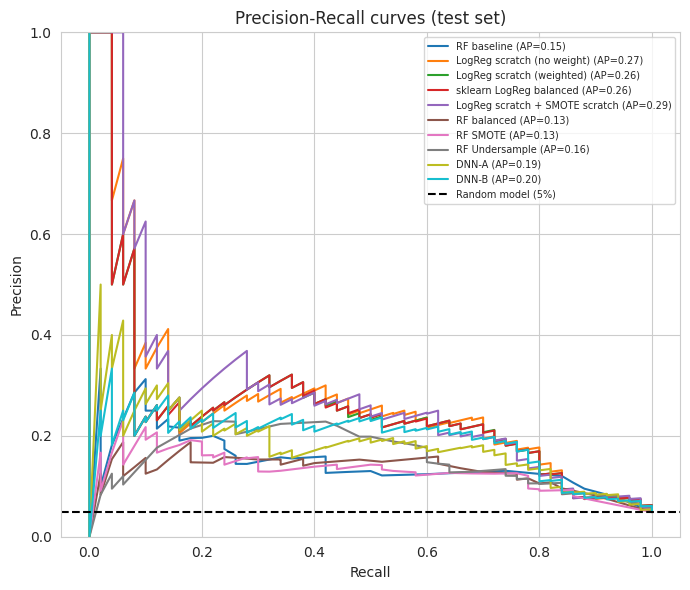

این نمودار نشان می‌دهد که مدل‌های بهتر بالای خط تصادفی (۵٪) هستند ولی Precision در Recall بالا پایین می‌آید؛ یعنی پیدا کردن بیماران بیشتر به هشدار اشتباه بیشتر می‌انجامد.


In [30]:
fig, ax = plt.subplots(figsize=(7, 6))
for nm, p in proba_dict.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=model_colors[nm], label=f"{nm} (AUC={results[nm]['AUC']:.2f})")
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_title("ROC curves (test set)"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (Recall)")
ax.legend(fontsize=7, loc="lower right")
save_show("19_roc_curves", "مدل‌های لجستیک و شبکه‌ی عصبی توان تفکیک (AUC) بالاتری از Random Forest دارند؛ ولی ROC در داده‌ی نامتوازن خوش‌بینانه است.")

fig, ax = plt.subplots(figsize=(7, 6))
for nm, p in proba_dict.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=model_colors[nm], label=f"{nm} (AP={results[nm]['PR_AUC']:.2f})")
ax.axhline(y_test.mean(), color="k", linestyle="--", label=f"Random model ({y_test.mean()*100:.0f}%)")
ax.set_title("Precision-Recall curves (test set)"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.legend(fontsize=7, loc="upper right"); ax.set_ylim(0, 1)
save_show("20_pr_curves", "مدل‌های بهتر بالای خط تصادفی (۵٪) هستند ولی Precision در Recall بالا پایین می‌آید؛ یعنی پیدا کردن بیماران بیشتر به هشدار اشتباه بیشتر می‌انجامد.")

**۸-الف) انتخاب مدل نهایی و آستانه (بدون استفاده از آزمون)**

**مدل نهایی: رگرسیون لجستیک وزن‌دار دست‌ساز.** دلایل: Recall آن (۰٫۸۰) هم‌سطح بهترین مدل‌هاست؛ AUC آن (۰٫۸۴) و PR_AUC آن (۰٫۲۶) از شبکه‌ی عمیق و همه‌ی نسخه‌های Random Forest بیشتر است؛ در اعتبارسنجی متقاطع هم AUC≈۰٫۸۴ داد (نتیجه‌ی پایدار)؛ ساده و برای پزشک قابل‌توضیح است (هر ضریب اثر یک عامل خطر است)؛ و نتیجه‌اش با scikit-learn یکسان است. مدل «لجستیک + SMOTE دست‌ساز» PR_AUC کمی بالاتر دارد (۰٫۲۸۷)، ولی Recall و AUC آن عملاً همان است و ساخت داده‌ی مصنوعی پیچیدگی اضافه می‌کند، پس نسخه‌ی وزن‌دار ساده‌تر ترجیح داده شد.

**آستانه:** با پیش‌بینی‌های اعتبارسنجی متقاطع ۵-تکه روی آموزش (Out-of-Fold) آستانه‌ای را انتخاب می‌کنیم که Recall ≥ ۰٫۸۰ بدهد و در بین آن‌ها بیشترین Precision را داشته باشد. فرض پزشکی: حداقل ۸۰٪ بیماران پیدا شوند (قابل تغییر با کمیته‌ی پزشکی).

In [31]:
FINAL_MODEL = "LogReg scratch (weighted)"
RECALL_TARGET = 0.80

# پیش‌بینی Out-of-Fold روی آموزش با مدل لجستیک وزن‌دار دست‌ساز
oof = np.zeros(len(y_train))
for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train_np, y_train):
    w_f, b_f, _ = train_logreg_gd(X_train_np[tr_i], y_train[tr_i], lr=LR_FINAL, n_iter=N_ITER, sample_w=balanced_sample_weights(y_train[tr_i]))
    oof[va_i] = predict_proba_lr(X_train_np[va_i], w_f, b_f)

ths = np.linspace(0.01, 0.99, 99)
P_oof, R_oof, F_oof = [], [], []
for t in ths:
    mt, _ = evaluate("tmp", y_train, oof, threshold=t, store=False)
    P_oof.append(mt["Precision"]); R_oof.append(mt["Recall"]); F_oof.append(mt["F1"])
P_oof, R_oof, F_oof = map(np.array, (P_oof, R_oof, F_oof))

ok = np.where(R_oof >= RECALL_TARGET)[0]
T_FINAL = float(ths[ok[np.argmax(P_oof[ok])]]) if len(ok) else float(ths[int(np.argmax(R_oof))])
print(f"آستانه‌ی انتخاب‌شده روی داده‌ی آموزش (OOF): {T_FINAL:.2f}")
print(f"در همین آستانه (OOF): Recall={R_oof[np.argmin(abs(ths-T_FINAL))]:.2f}, Precision={P_oof[np.argmin(abs(ths-T_FINAL))]:.2f}")
print(f"PR_AUC روی OOF: {average_precision_score(y_train, oof):.3f} | AUC روی OOF: {roc_auc_score(y_train, oof):.3f}")

آستانه‌ی انتخاب‌شده روی داده‌ی آموزش (OOF): 0.50
در همین آستانه (OOF): Recall=0.82, Precision=0.14
PR_AUC روی OOF: 0.175 | AUC روی OOF: 0.838


**۸-ب) اثر تغییر آستانه‌ی تصمیم‌گیری (۰٫۲ تا ۰٫۶) روی مدل نهایی — گزارش روی آزمون**

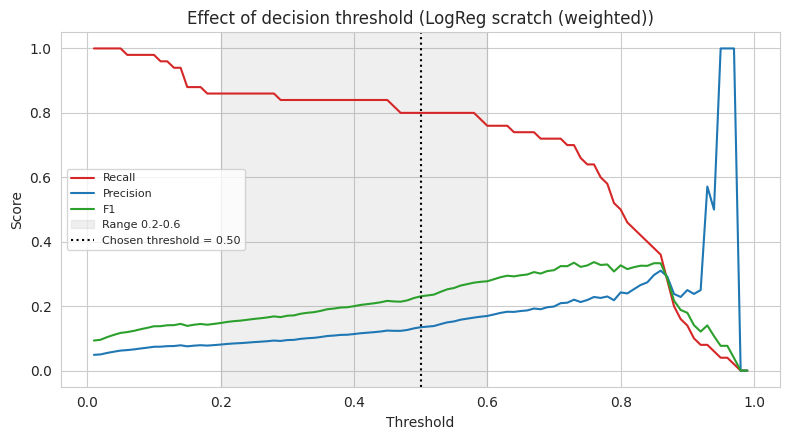

این نمودار نشان می‌دهد که با کم‌کردن آستانه Recall بالا می‌رود و Precision پایین می‌آید؛ باید نقطه‌ای را برگزید که پزشک بپذیرد.


,threshold,Recall,Precision,F1,TP (patients found),FN (patients missed),FP (false alarms)
0,0.2,0.86,0.081,0.148,43,7,489
1,0.3,0.84,0.095,0.170,42,8,401
2,0.4,0.84,0.114,0.200,42,8,328
3,0.5,0.80,0.135,0.231,40,10,257
4,0.6,0.76,0.170,0.277,38,12,186


In [32]:
p_final = proba_dict[FINAL_MODEL]
P, R, F = [], [], []
for t in ths:
    mt, _ = evaluate("tmp", y_test, p_final, threshold=t, store=False)
    P.append(mt["Precision"]); R.append(mt["Recall"]); F.append(mt["F1"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ths, R, label="Recall", color=COL_PATIENT); ax.plot(ths, P, label="Precision", color=COL_HEALTHY); ax.plot(ths, F, label="F1", color="#2ca02c")
ax.axvspan(0.2, 0.6, color="gray", alpha=0.12, label="Range 0.2-0.6")
ax.axvline(T_FINAL, color="k", linestyle=":", label=f"Chosen threshold = {T_FINAL:.2f}")
ax.set_title(f"Effect of decision threshold ({FINAL_MODEL})"); ax.set_xlabel("Threshold"); ax.set_ylabel("Score"); ax.legend(fontsize=8)
save_show("21_threshold_effect", "با کم‌کردن آستانه Recall بالا می‌رود و Precision پایین می‌آید؛ باید نقطه‌ای را برگزید که پزشک بپذیرد.")

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, round(T_FINAL, 2)]:
    mt, cmt = evaluate("tmp", y_test, p_final, threshold=t, store=False)
    tn_, fp_, fn_, tp_ = (int(v) for v in cmt.ravel())
    rows.append({"threshold": t, "Recall": mt["Recall"], "Precision": mt["Precision"], "F1": mt["F1"],
                 "TP (patients found)": tp_, "FN (patients missed)": fn_, "FP (false alarms)": fp_})
display(pd.DataFrame(rows).round(3).drop_duplicates("threshold"))

**۸-پ) مقایسه‌ی هزینه‌ی دو نوع خطا**
- **هشدار اشتباه (FP):** یک معاینه‌ی اضافی برای فرد سالم (چند دقیقه وقت پزشک و شاید یک آزمایش).
- **نادیده‌گرفتن بیمار (FN):** از دست رفتن زمان طلایی درمان، ناتوانی دائمی یا مرگ.

در سلول زیر یک **فرض عددی** قرار داده شده (قابل تغییر): هر FN = ۵۰ واحد و هر FP = ۱ واحد. این عددها فرض‌اند و باید با کمیته‌ی پزشکی تنظیم شوند. هزینه‌ها روی پیش‌بینی‌های Out-of-Fold آموزش محاسبه شده‌اند تا آزمون دست‌نخورده بماند؛ سپس هزینه‌ی آستانه‌ی نهایی روی آزمون گزارش می‌شود.

هزینه‌ی میانگین هر بیمار (OOF): بدون مدل = 2.43 | کمترین هزینه با مدل = 0.54 (آستانه 0.18)

روی آزمون (فقط گزارش):
  هزینه‌ی کل اگر هیچ هشداری ندهیم (همه سالم): 2500
  هزینه‌ی کل اگر برای همه هشدار بدهیم:       972
  هزینه‌ی کل با مدل نهایی در آستانه‌ی 0.50: 757
  Recall=0.80, Precision=0.13, ماتریس (TN,FP,FN,TP)=(715, 257, 10, 40)


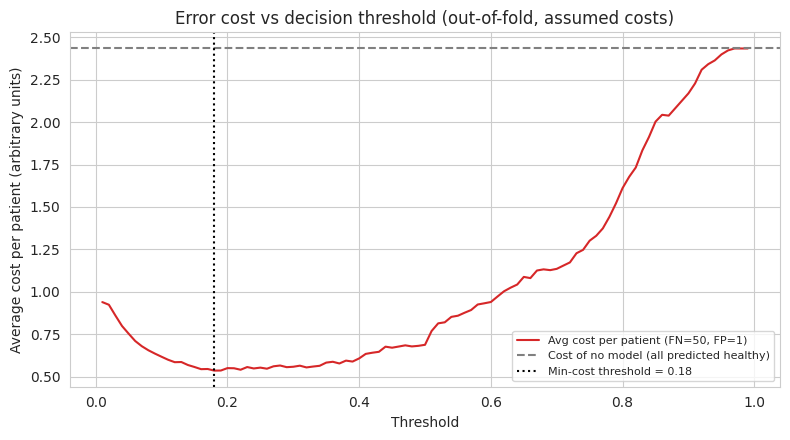

این نمودار نشان می‌دهد که استفاده از مدل با آستانه‌ی پایین، هزینه‌ی کل خطاها را نسبت به «هیچ هشداری ندادن» کم می‌کند.


In [33]:
COST_FN, COST_FP = 50, 1

def total_cost(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return COST_FN * int(((pred == 0) & (y_true == 1)).sum()) + COST_FP * int(((pred == 1) & (y_true == 0)).sum())

costs_oof = np.array([total_cost(y_train, oof, t) for t in ths]) / len(y_train)   # هزینه‌ی میانگین برای هر بیمار
t_cost = float(ths[int(np.argmin(costs_oof))])
no_model_oof = COST_FN * y_train.sum() / len(y_train)
print(f"هزینه‌ی میانگین هر بیمار (OOF): بدون مدل = {no_model_oof:.2f} | کمترین هزینه با مدل = {costs_oof.min():.2f} (آستانه {t_cost:.2f})")

n_pos, n_neg = int(y_test.sum()), int((y_test == 0).sum())
print(f"\nروی آزمون (فقط گزارش):")
print(f"  هزینه‌ی کل اگر هیچ هشداری ندهیم (همه سالم): {COST_FN*n_pos}")
print(f"  هزینه‌ی کل اگر برای همه هشدار بدهیم:       {COST_FP*n_neg}")
print(f"  هزینه‌ی کل با مدل نهایی در آستانه‌ی {T_FINAL:.2f}: {total_cost(y_test, p_final, T_FINAL)}")
mt, cmt = evaluate("tmp", y_test, p_final, threshold=T_FINAL, store=False)
print(f"  Recall={mt['Recall']:.2f}, Precision={mt['Precision']:.2f}, ماتریس (TN,FP,FN,TP)={tuple(int(v) for v in cmt.ravel())}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ths, costs_oof, color=COL_PATIENT, label=f"Avg cost per patient (FN={COST_FN}, FP={COST_FP})")
ax.axhline(no_model_oof, color="gray", linestyle="--", label="Cost of no model (all predicted healthy)")
ax.axvline(t_cost, color="k", linestyle=":", label=f"Min-cost threshold = {t_cost:.2f}")
ax.set_title("Error cost vs decision threshold (out-of-fold, assumed costs)")
ax.set_xlabel("Threshold"); ax.set_ylabel("Average cost per patient (arbitrary units)"); ax.legend(fontsize=8)
save_show("22_threshold_cost", "استفاده از مدل با آستانه‌ی پایین، هزینه‌ی کل خطاها را نسبت به «هیچ هشداری ندادن» کم می‌کند.")

**۸-ت) اهمیت ویژگی‌ها (Random Forest با `class_weight='balanced'`)**

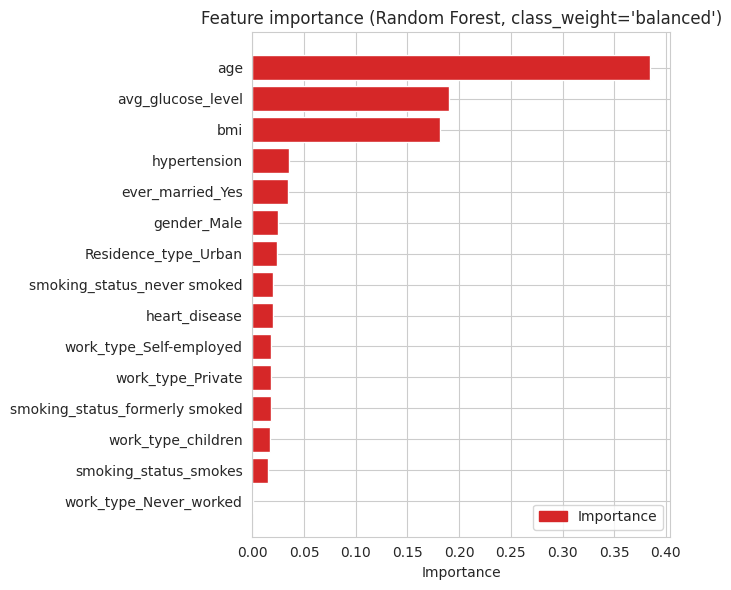

این نمودار نشان می‌دهد که سن مهم‌ترین عامل است و قند خون و BMI در رتبه‌های بعدی قرار دارند (متغیرهای پیوسته در درخت‌ها بیشتر برای شکستن استفاده می‌شوند).
age                  0.385
avg_glucose_level    0.190
bmi                  0.181
hypertension         0.036
ever_married_Yes     0.034
dtype: float64

بزرگ‌ترین ضرایب مدل نهایی (لجستیک وزن‌دار؛ ویژگی‌های عددی استاندارد شده‌اند):
age                            1.902
work_type_children             1.028
hypertension                   0.633
smoking_status_smokes          0.300
work_type_Never_worked        -0.256
smoking_status_never smoked   -0.230
dtype: float64


In [34]:
imp = pd.Series(rf_bal.feature_importances_, index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color=COL_PATIENT)
ax.set_title("Feature importance (Random Forest, class_weight='balanced')"); ax.set_xlabel("Importance")
ax.legend([Patch(color=COL_PATIENT)], ["Importance"], loc="lower right")
save_show("23_feature_importance", "سن مهم‌ترین عامل است و قند خون و BMI در رتبه‌های بعدی قرار دارند (متغیرهای پیوسته در درخت‌ها بیشتر برای شکستن استفاده می‌شوند).")
print(imp.sort_values(ascending=False).head(5).round(3))

coef_final = pd.Series(w_wtd, index=feature_names).sort_values(key=abs, ascending=False)
print("\nبزرگ‌ترین ضرایب مدل نهایی (لجستیک وزن‌دار؛ ویژگی‌های عددی استاندارد شده‌اند):"); print(coef_final.head(6).round(3))

**۸-ث) شکل خلاصه‌ی ۲×۲ **

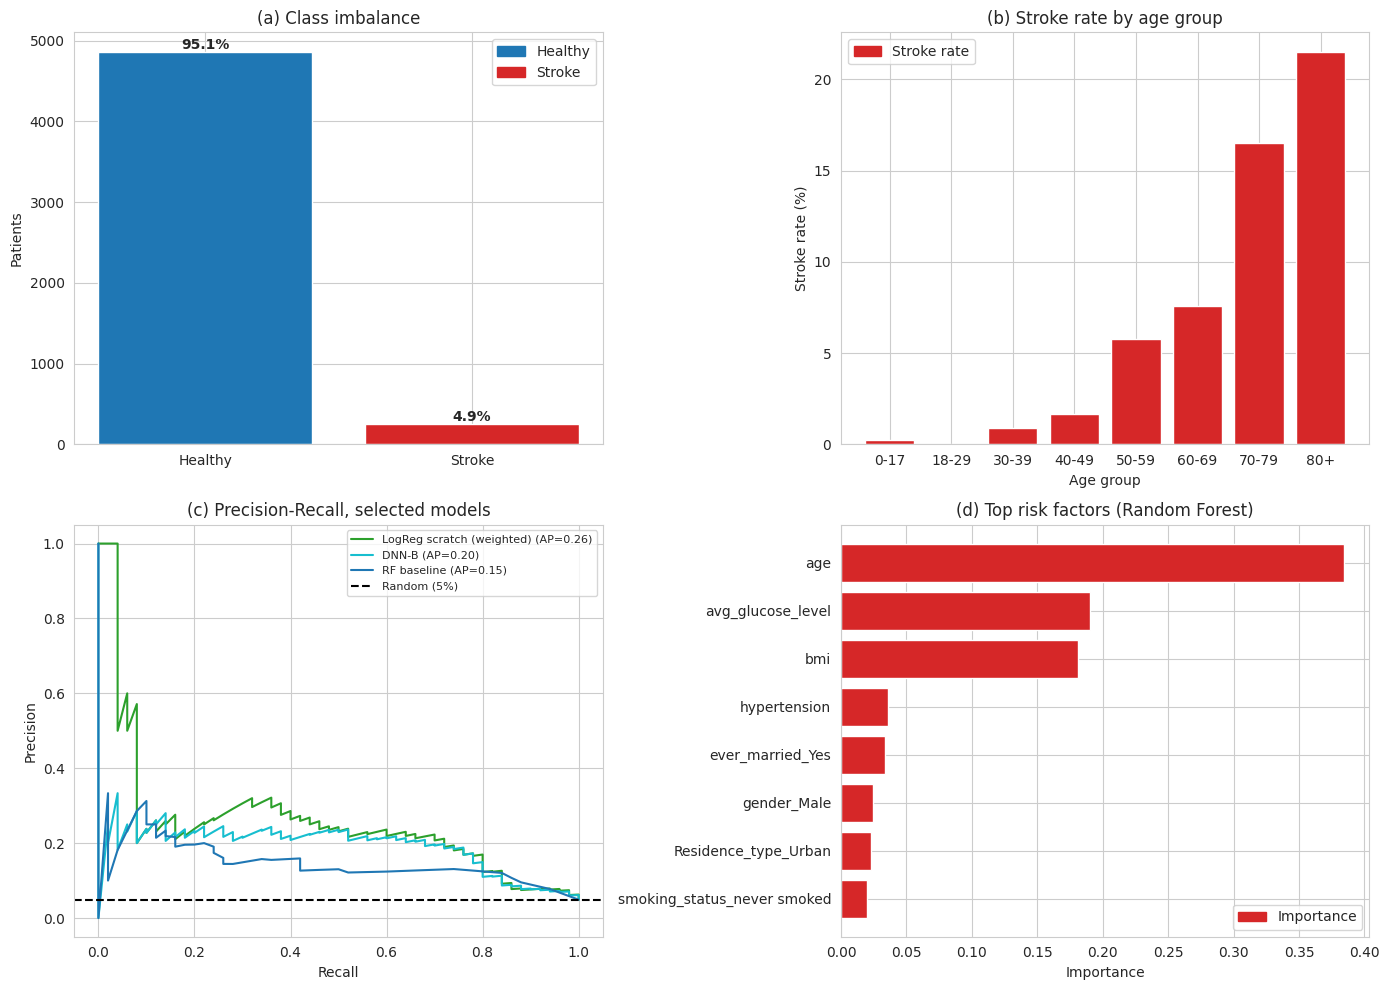

این نمودار نشان می‌دهد که داده نامتوازن است، سن عامل اصلی خطر است، مدل نهایی بسیار بالاتر از حالت تصادفی عمل می‌کند و مهم‌ترین عوامل خطر مشخص شده‌اند.


In [35]:
top3 = [FINAL_MODEL, "DNN-B", "RF baseline"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cnt = df_clean["stroke"].value_counts().sort_index(); pc = cnt / cnt.sum() * 100
axes[0, 0].bar(["Healthy", "Stroke"], cnt.values, color=[COL_HEALTHY, COL_PATIENT])
for i, v in enumerate(pc.values): axes[0, 0].text(i, cnt.values[i] + 40, f"{v:.1f}%", ha="center", fontweight="bold")
axes[0, 0].set_title("(a) Class imbalance"); axes[0, 0].set_ylabel("Patients")
legend_for(axes[0, 0], [("Healthy", COL_HEALTHY), ("Stroke", COL_PATIENT)])

axes[0, 1].bar(rate_age.index.astype(str), rate_age.values, color=COL_PATIENT)
axes[0, 1].set_title("(b) Stroke rate by age group"); axes[0, 1].set_ylabel("Stroke rate (%)"); axes[0, 1].set_xlabel("Age group")
legend_for(axes[0, 1], [("Stroke rate", COL_PATIENT)])

for nm in top3:
    pr_, rc_, _ = precision_recall_curve(y_test, proba_dict[nm])
    axes[1, 0].plot(rc_, pr_, color=model_colors[nm], label=f"{nm} (AP={results[nm]['PR_AUC']:.2f})")
axes[1, 0].axhline(y_test.mean(), color="k", linestyle="--", label="Random (5%)")
axes[1, 0].set_title("(c) Precision-Recall, selected models"); axes[1, 0].set_xlabel("Recall"); axes[1, 0].set_ylabel("Precision"); axes[1, 0].legend(fontsize=8)

top_imp = imp.tail(8)
axes[1, 1].barh(top_imp.index, top_imp.values, color=COL_PATIENT)
axes[1, 1].set_title("(d) Top risk factors (Random Forest)"); axes[1, 1].set_xlabel("Importance")
legend_for(axes[1, 1], [("Importance", COL_PATIENT)], loc="lower right")
save_show("00_summary_2x2", "داده نامتوازن است، سن عامل اصلی خطر است، مدل نهایی بسیار بالاتر از حالت تصادفی عمل می‌کند و مهم‌ترین عوامل خطر مشخص شده‌اند.")

## پاسخ‌های نهایی فاز ۸

**اگر شما مدیر بیمارستان بودید، کدام مدل و کدام آستانه را انتخاب می‌کردید؟**


**مدل:** رگرسیون لجستیک وزن‌دار

 دلیل‌ها: AUC (۰٫۸۴) و PR_AUC (۰٫۲۶) آن از شبکه‌ی عمیق و Random Forest کمتر نیست؛ در اعتبارسنجی متقاطع هم AUC≈۰٫۸۴ داد (نتیجه‌ی پایدار)؛ ساده و قابل‌توضیح برای پزشک است؛ و ضرایبش با scikit-learn تأیید شد.

**آستانه:** ۰٫۵۰. این مقدار با پیش‌بینی‌های Out-of-Fold روی داده‌ی آموزش انتخاب شد: بیشترین Precision در میان آستانه‌هایی که Recall ≥ ۰٫۸۰ دارند (Recall=۰٫۸۲ و Precision=۰٫۱۴). روی آزمون (فقط گزارش): ۴۰ از ۵۰ بیمار پیدا شدند (Recall=۰٫۸۰)، ۱۰ بیمار از دست رفتند و ۲۵۷ هشدار اشتباه داده شد (Precision≈۰٫۱۳، یعنی از هر ۷ تا ۸ هشدار یکی بیمار واقعی است).
اگر کمیته‌ی پزشکی خطای نادیده‌گرفتن بیمار را سنگین‌تر بداند، آستانه‌ی پایین‌تر مناسب است؛ با هزینه‌ی فرضی ۵۰ به ۱ آستانه‌ی کمینه‌ی هزینه ≈۰٫۱۸ شد (نمودار ۲۲) و در بازه‌ی ۰٫۲ روی آزمون Recall=۰٫۸۶ ولی ۴۸۹ هشدار اشتباه به دست آمد. انتخاب نهایی بین این دو نقطه با کمیته است. این سامانه **غربالگری** است، نه تشخیص؛ فرد علامت‌خورده فقط زودتر توسط پزشک دیده می‌شود.

**مقایسه‌ی هزینه‌ی هشدار اشتباه و نادیده‌گرفتن بیمار:**
هشدار اشتباه یعنی یک معاینه‌ی اضافی (کم‌هزینه و قابل جبران)، ولی نادیده‌گرفتن بیمار یعنی از دست رفتن زمان طلایی درمان و احتمال ناتوانی دائمی یا مرگ. با هزینه‌ی فرضی ۵۰ به ۱، روی آزمون هزینه‌ی کل «هیچ هشداری ندادن» ۲۵۰۰، «برای همه هشدار دادن» ۹۷۲ و «مدل نهایی در آستانه‌ی ۰٫۵» ۷۵۷ است. پس ارزش دارد مقداری Precision را فدا کنیم تا Recall بالا برود.

**محدودیت‌ها:**
1. فقط حدود ۲۵۰ بیمار در کل داده (۵۰ بیمار در آزمون)؛ نتایج، به‌ویژه Recall، ناپایدارند و بازه‌ی اطمینان وسیعی دارند.
2. دیتاست عمومی است و ممکن است برای بیمارستان شما تعمیم نیابد؛ حدود ۱۲۰ نمونه‌ی زیر ۲ سال هم دارد.
3. عوامل مهمی مثل کلسترول، فیبریلاسیون دهلیزی و سابقه‌ی خانوادگی در داده نیست.
4. هزینه‌های ۵۰ به ۱ فرضی‌اند.
5. ضرایب ویژگی‌های همبسته با سن (مثل `work_type_children`) را نباید مستقیم «عامل خطر» تفسیر کرد.
6. SMOTE روی ستون‌های صفر/یک مقدار اعشاری می‌سازد (راه‌حل: SMOTENC).
7. قبل از استفاده‌ی بالینی، اعتبارسنجی با داده‌ی واقعی بیمارستان و تأیید کمیته‌ی پزشکی لازم است.